# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis


1. NLP  
2. Time Series  
3. Neural Networks  



## Part 1: NLP

In this section, I will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


# Part 1: Natural Language Processing (NLP)

## Scenario and goal

I am a junior data scientists at an analytics firm. A support team receives many customer reviews and needs a quick way to understand what customers are discussing and which reviews may need attention.



Goal:
To develop a system that analyzes customer reviews, identifies common topics and sentiments, and flags reviews that may require attention, helping the support team understand customer feedback quickly and respond effectively.


- explore the supplied amazon_reviews_lab.csv dataset
-  clean the review text
- identify common words and phrases
- compare language across sentiment groups
-  build a small demonstration tool that predicts sentiment and suggests a support topic.


## Step 1: Import the libraries

In [50]:
# Import libraries and set reproducible random seeds

# General utilities
import os
import re
import html
import string
import random
import warnings
from pathlib import Path
from collections import Counter

# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Natural Language Processing (NLP)
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.util import ngrams

# Machine learning: data splitting and validation
from sklearn.model_selection import (
    train_test_split,
    cross_val_predict,
    StratifiedKFold
)

# Machine learning: preprocessing and text features
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline

# Machine learning: models and baselines
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.utils.class_weight import compute_class_weight

# Machine learning: evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Deep learning: TensorFlow/Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Deep learning: PyTorch
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader

    TORCH_AVAILABLE = True
except ImportError:
    TORCH_AVAILABLE = False
    print("PyTorch is not installed; PyTorch models will be skipped.")

# Transformer models (optional)
try:
    from transformers import (
        AutoTokenizer,
        AutoModelForSequenceClassification
    )

    TRANSFORMERS_AVAILABLE = True
except ImportError:
    TRANSFORMERS_AVAILABLE = False
    print("Transformers is not installed; transformer models will be skipped.")

# Time-series analysis and forecasting
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

# Set random seeds for reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

if TORCH_AVAILABLE:
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

# Download required NLTK resources
for package in [
    "punkt",
    "punkt_tab",
    "stopwords",
    "wordnet",
    "omw-1.4"
]:
    nltk.download(package, quiet=True)

# Configure visualizations
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 5)

# Keep notebook output readable
warnings.filterwarnings("ignore")

# Confirm successful imports
print("Libraries loaded successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)
print("PyTorch available:", TORCH_AVAILABLE)
print("Transformers available:", TRANSFORMERS_AVAILABLE)


Libraries loaded successfully.
NumPy version: 2.1.3
Pandas version: 2.2.3
TensorFlow version: 2.21.0
PyTorch available: True
Transformers available: True


In [56]:
# Initialize NLP tools
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


# Define the text-preprocessing function
def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    if not isinstance(text, str):
        return []

    # Convert to lowercase and remove HTML tags
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Keep letters and spaces
    text = re.sub(r"[^a-zA-Z\s]", " ", text.lower())

    # Tokenize text
    tokens = word_tokenize(text)

    # Remove stopwords if requested
    if remove_stopwords:
        tokens = [
            word for word in tokens
            if word not in stop_words
        ]

    # Lemmatize words if requested
    if lemmatize:
        tokens = [
            lemmatizer.lemmatize(
                lemmatizer.lemmatize(word, pos="n"),
                pos="v"
            )
            for word in tokens
        ]

    return tokens


## Step 2: Load and explore the dataset

Before cleaning text;

- I will check the size, columns, missing values, star ratings, sentiment labels, and a few example reviews.

This helps me understand what is in the data and whether anything needs attention.

In [57]:
# Load the Amazon reviews dataset
df = pd.read_csv('amazon_reviews_lab.csv')

# Display the dataset information
print('Shape (rows, columns):', df.shape)
print('\nColumns:', list(df.columns))
print('\nMissing values per column:')
print(df.isna().sum())

# Display rating and sentiment distributions
print('\nRating counts:')
print(df['rating'].value_counts().sort_index())

print('\nSentiment label counts:')
print(df['sentiment_label'].value_counts())

# Preview the first five reviews
df[['product_id', 'rating', 'review_summary', 'review_text', 'sentiment_label']].head()

Shape (rows, columns): (997, 9)

Columns: ['product_id', 'rating', 'review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label', 'review_length_words']

Missing values per column:
product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

Rating counts:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Sentiment label counts:
sentiment_label
positive    768
negative    135
neutral      94
Name: count, dtype: int64


,product_id,rating,review_summary,review_text,sentiment_label
0,6301977173,2,The best of Mark Twain's work - left out!,This film is definitely not for anyone who is ...,negative
1,6301977173,5,The best Tom Sawyer i ever saw.,This movie was playing at Radio City Music Hal...,positive
2,6301977173,1,Why no Widescreen?,I would love to buy this movie as I have been ...,negative
3,6301977173,1,False advertising on this DVD,The advertisment for this DVD on Amazon was in...,negative
4,9575871979,5,Work GREAT!!,I bought some of these to try with a light usi...,positive


- The dataset contains 997 customer reviews and 9 columns.
- There are no missing values
- The main columns for this analysis are:

  a. review_text: Contains the full customer review.

  b. review_summary: Contains a short title or summary of the review.

  c. rating: Contains the customer's rating from 1 to 5 stars.
  
  d. sentiment_label: Categorizes each review as positive, neutral, or negative.


- The ratings are imbalanced because some ratings occur much more frequently than others. For example, 580 reviews have 5 stars, while only 87 reviews have 1 star.
- The sentiment_label is derived from the star rating:

    - 1 - 2 stars: Negative

    - 3 stars: Neutral

    - 4 - 5 stars: Positive

These sentiment labels provide categories for analysing customer opinions and developing a review-classification and routing system.

During model evaluation, metrics such as precision, recall, F1-score, and a confusion matrix should be considered alongside accuracy to assess how well the model identifies each sentiment category.

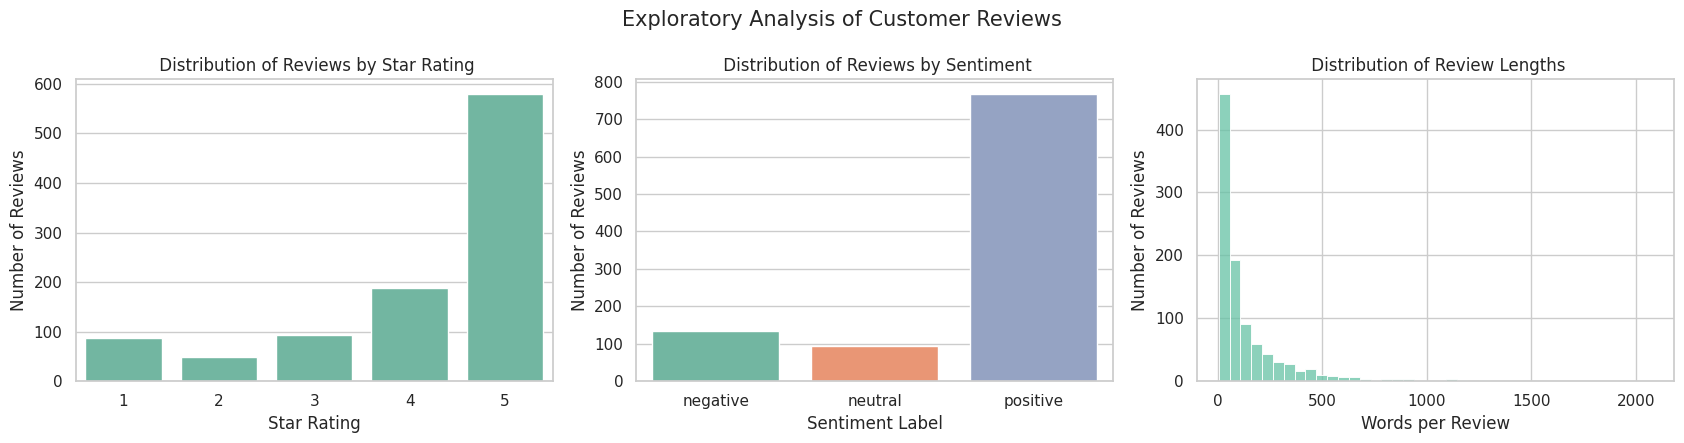

Summary Statistics for Review Length (Words):
count     997.0
mean      146.4
std       216.1
min         5.0
25%        32.0
50%        67.0
75%       165.0
max      2079.0
Name: review_length_words, dtype: float64

Average Review Length by Star Rating:
rating
1    202.1
2    226.1
3    195.5
4    168.1
5    116.4
Name: review_length_words, dtype: float64


In [58]:
# Explore the rating and sentiment distributions

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot 1: Number of reviews per star rating
sns.countplot(x='rating', data=df, ax=ax[0])
ax[0].set_title(' Distribution of Reviews by Star Rating')
ax[0].set_xlabel('Star Rating')
ax[0].set_ylabel('Number of Reviews')

# Plot 2: Number of reviews per sentiment label
order = ['negative', 'neutral', 'positive']
sns.countplot(
    x='sentiment_label',
    data=df,
    order=order,
    hue='sentiment_label',
    hue_order=order,
    legend=False,
    ax=ax[1]
)
ax[1].set_title(' Distribution of Reviews by Sentiment')
ax[1].set_xlabel('Sentiment Label')
ax[1].set_ylabel('Number of Reviews')

# Plot 3: Distribution of review lengths
sns.histplot(df['review_length_words'], bins=40, ax=ax[2])
ax[2].set_title(' Distribution of Review Lengths')
ax[2].set_xlabel('Words per Review')
ax[2].set_ylabel('Number of Reviews')

# Add an overall heading and display all three plots
fig.suptitle('Exploratory Analysis of Customer Reviews', fontsize=15)
plt.tight_layout()
plt.show()

# Summarize review length statistics
print('Summary Statistics for Review Length (Words):')
print(df['review_length_words'].describe().round(1))

# Compare average review length by star rating
print('\nAverage Review Length by Star Rating:')
print(df.groupby('rating')['review_length_words'].mean().round(1))

- The exploratory analysis of customer reviews graph show that  Most customers are happy with the products. Positive reviews are  (768 reviews), negative reviews  (135 reviews), and neutral reviews  (94 reviews).


- Customers giving lower ratings tend to write longer reviews. For example, 2-star reviews average 202.1 words, compared with 116.4 words for 5-star reviews. This may mean unhappy customers explain their problems in more detail, while happy customers often write shorter feedback.

- Reviews vary greatly in length, so text preprocessing is important to prepare both short and long reviews for NLP analysis.

## Step 3: Data Preprocessing

Text need special cleaning because Computers cannot understand sentences the way we do. To a computer, Great!, great and GREAT are three different strings. Raw reviews also contain noise that carries no meaning.

In [59]:
# Check the review text for HTML codes and URLs before cleaning
html_noise = df['review_text'].str.contains(r'&quot;|&amp;|&#\d+;|<br', regex=True).sum()
url_noise  = df['review_text'].str.contains(r'http|www\.', regex=True).sum()
print(f'Reviews containing HTML codes like &quot; or <br>: {html_noise}')
print(f'Reviews containing web links: {url_noise}')

sample = df.loc[df['review_text'].str.contains('&quot;'), 'review_text'].iloc[0]
print('\nExample of a messy review (first 300 characters):\n')
print(sample[:300])

Reviews containing HTML codes like &quot; or <br>: 73
Reviews containing web links: 1

Example of a messy review (first 300 characters):

This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book has great fun with the scenes involving Aunt Polly, a simple minded soul who thinks herself quite cl


# Result
 - 73 reviews contain leftover HTML codes, such as &quot;, which represents a quotation mark.

 - One review contains a link.


 If not cleaned, these codes could appear as misleading frequent words during text analysis.This shows why we must check that our cleaning process works correctly.

# Text Cleaning Plan
  - Fix HTML codes: Convert codes like &quot; into their correct characters.
  - Convert to lowercase: Ensure words like Great and great are treated the same.
  - Remove URLs and HTML tags: Remove links and webpage formatting.
  - Remove punctuation: Prevent punctuation from interfering with word analysis.
  - Tokenize text: Split each review into individual words.
  - Keep useful words: Remove numbers, short fragments, and non-alphabetic tokens.
  - Remove stopwords: Remove common words like the, is, and and that add little meaning.
  - Lemmatize words: Convert words to their base forms, such as batteries to battery and working to work.
 - Keep negation words: Retain not, no, nor, and never because they can change a review's meaning and are important for sentiment analysis.
 - Add filler words to stopwords: Remove common words such as would, could, and also when they add little useful information.


## Step 4: Build the preprocessing tools and function

Here I create the stopword list and the lemmatizer, then write one function, preprocess_text(), that carries out all the steps  above and returns a clean list of tokens.

In [60]:
# Prepare stopwords while keeping important negation words
# Standard English stopwords, but KEEP the negations because they flip the meaning
stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor', 'never'}

# A few extra filler words that appear in nearly every review
extra_fillers = {'would', 'could', 'also', 'get', 'got', 'one', 'even', 'really',
                 'still', 'much', 'make', 'ever', 'thing', 'let', 'amp', 'quot'}
stop_words |= extra_fillers

lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()      # only used below to COMPARE with lemmatizing

print('Number of stopwords we remove:', len(stop_words))
print('Negations kept:', {'not', 'no', 'nor', 'never'} - stop_words)

Number of stopwords we remove: 211
Negations kept: {'never', 'not', 'no', 'nor'}


In [ ]:
# Define a function to clean and preprocess each review
def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """Clean one review and return a list of cleaned tokens."""
    # 0. fix HTML codes such as &quot; and remove html tags such as <br />
    text = html.unescape(str(text))
    text = re.sub(r'<[^>]+>', ' ', text)
    # 1. lowercase
    text = text.lower()
    # 2. remove URLs
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # 3. remove punctuation (replace with a space so 'well-made' becomes 'well made')
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))
    # 4. tokenize
    tokens = word_tokenize(text)
    # 5. keep alphabetic tokens only, longer than 2 letters (drops numbers and fragments)
    tokens = [t for t in tokens if t.isalpha() and len(t) > 2]
    # 6. remove stopwords
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    # 7. lemmatize (noun form first, then verb form: 'batteries'->'battery', 'working'->'work')
    if lemmatize:
        tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, pos='n'), pos='v') for t in tokens]
    # 8. return cleaned tokens
    return tokens

# Quick test on one sentence
test = "I LOVE this Nook!! The batteries last 2 days &quot;easily&quot; - see http://example.com. Not working well, though."
print('Before:', test)
print('After :', preprocess_text(test))

Before: I LOVE this Nook!! The batteries last 2 days &quot;easily&quot; - see http://example.com. Not working well, though.
After : ['love', 'nook', 'battery', 'last', 'day', 'easily', 'see', 'not', 'work', 'well', 'though']


# What happened in the test
 - The uppercase word LOVE became love.
 - The number 2, the URL, and punctuation were removed.
 - The HTML code &quot; is decoded into quotation marks, which are then removed during cleaning.
 - batteries became battery, and working became work through lemmatization.
 - not is still there because it preserves the negative meaning of the review.

## Step 5: How each step changes the text

  - I will experiment with tokenization, stopword removal, and lemmatization or stemming.
  - I will use one real review to see how the number of words changes after each step.
  - I will also compare stemming, which removes word endings, with lemmatization, which converts words to their dictionary forms.

In [61]:
# Test the text-preprocessing function on an example review
example = df.loc[df['rating'] == 1, 'review_text'].iloc[3]
print('Original review (first 250 chars):\n', example[:250], '...\n')

raw_tokens      = word_tokenize(example.lower())
cleaned_no_lemma = preprocess_text(example, remove_stopwords=True, lemmatize=False)
cleaned_keep_stopwords = preprocess_text(example, remove_stopwords=False, lemmatize=True)
full = preprocess_text(example)

print('Tokens after plain tokenizing (with punctuation, stopwords) :', len(raw_tokens))
print('Tokens after cleaning + lemmatizing, KEEPING stopwords      :', len(cleaned_keep_stopwords))
print('Tokens after cleaning + removing stopwords, no lemmatizing  :', len(cleaned_no_lemma))
print('Final tokens (stopwords removed + lemmatized)               :', len(full))

# Stemming vs lemmatizing on some words
words = ['batteries', 'working', 'readers', 'charging', 'screens', 'bought', 'easily', 'better']
comp = pd.DataFrame({'original': words,
                     'stem (Porter)': [stemmer.stem(w) for w in words],
                     'lemma': [lemmatizer.lemmatize(lemmatizer.lemmatize(w, 'n'), 'v') for w in words]})
comp

Original review (first 250 chars):
 I'll admit up front that when I chose the Nook over Kindle and Sony's e-reader, I was impressed by that nifty full color touchscreen at the bottom of reading screen. Glitz does not equal function, as I promptly found out.To be fair to Nook, if ALL yo ...

Tokens after plain tokenizing (with punctuation, stopwords) : 607
Tokens after cleaning + lemmatizing, KEEPING stopwords      : 525
Tokens after cleaning + removing stopwords, no lemmatizing  : 275
Final tokens (stopwords removed + lemmatized)               : 275


,original,stem (Porter),lemma
0,batteries,batteri,battery
1,working,work,work
2,readers,reader,reader
3,charging,charg,charge
4,screens,screen,screen
5,bought,bought,buy
6,easily,easili,easily
7,better,better,better


- Tokenization and cleaning:

The original review contains 607 tokens. After cleaning and lemmatization, 525 tokens remain when stopwords are kept. Removing stopwords reduces the count further to 275 tokens.

- Stemming vs. lemmatization:

Stemming removes word endings and can produce incomplete words, such as batteries - batteri and easily - easili. Lemmatization produces meaningful base words, such as batteries - battery and bought - buy.

- I choose lemmatization because It produces readable words that are easier to interpret in charts and explain to a support team.

- Cleaning reduces unnecessary text and helps the classifier focus on useful words. However, removing too much information can affect sentiment analysis, so I keep negation words such as not.

- The final token count is 267, the same as the count after stopword removal without lemmatization. This suggests that lemmatization changed word forms without changing the number of tokens .

## Step 6: Apply the cleaning to every review

- I will apply preprocess_text() to all 997 reviews and save the cleaned tokens in a new column called processed_tokens.

- Create a clean_text column by joining the tokens into plain text for the classifier.

- Finally, I will validate the results by checking how many tokens were removed and whether any reviews became empty after preprocessing.

In [62]:
# Preprocess all reviews and check how much the text was cleaned
df['processed_tokens'] = df['review_text'].apply(preprocess_text)
df['clean_text'] = df['processed_tokens'].apply(' '.join)

# Validation checks
raw_count   = df['review_text'].apply(lambda t: len(word_tokenize(str(t)))).sum()
clean_count = df['processed_tokens'].apply(len).sum()
print(f'Tokens before cleaning (incl. punctuation): {raw_count:,}')
print(f'Tokens after cleaning                     : {clean_count:,}')
print(f'Reduction                                  : {100*(1-clean_count/raw_count):.1f}%')
print('Reviews that became empty after cleaning   :', (df['processed_tokens'].apply(len) == 0).sum())
print('Leftover junk tokens (quot, amp, br)        :',
      sum(t in {'quot', 'amp', 'br'} for toks in df['processed_tokens'] for t in toks))

df[['review_text', 'processed_tokens']].head(3)

Tokens before cleaning (incl. punctuation): 167,738
Tokens after cleaning                     : 70,951
Reduction                                  : 57.7%
Reviews that became empty after cleaning   : 0
Leftover junk tokens (quot, amp, br)        : 0


,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, not, anyone, especially, fo..."
1,This movie was playing at Radio City Music Hal...,"[movie, play, radio, city, music, hall, back, ..."
2,I would love to buy this movie as I have been ...,"[love, buy, movie, hannibal, missouri, mark, t..."


- Cleaning reduced the tokens by 57.7%, from 167,738 to 70,951, removing mostly punctuation, stopwords, and other unnecessary text.
- No review became empty, so every review still contains words that can be analysed.
- No leftover junk tokens like quot, amp, or br were found, showing that the HTML cleaning worked correctly.

## Step 7: Most common words

Now that the text is clean, I can analyse word frequency , combine the tokens from all reviews into one list and use Counter to count how often each word appears. The most frequent words help me identify the topics customers mention most often in their reviews.

In [63]:
# Count all cleaned words and display the most common words
all_tokens = [tok for toks in df['processed_tokens'] for tok in toks]
word_counts = Counter(all_tokens)

print('Total tokens        :', len(all_tokens))
print('Unique words (vocab):', len(word_counts))
print('\nTop 25 words:')
for w, c in word_counts.most_common(25):
    print(f'{w:12s} {c}')

Total tokens        : 70951
Unique words (vocab): 5549

Top 25 words:
nook         1580
not          1064
book         986
use          805
read         763
work         626
kindle       605
buy          595
screen       537
like         508
great        444
tablet       444
tv           427
mount        409
no           408
device       399
n            376
go           363
good         350
b            348
reader       346
want         341
well         336
time         331
need         316


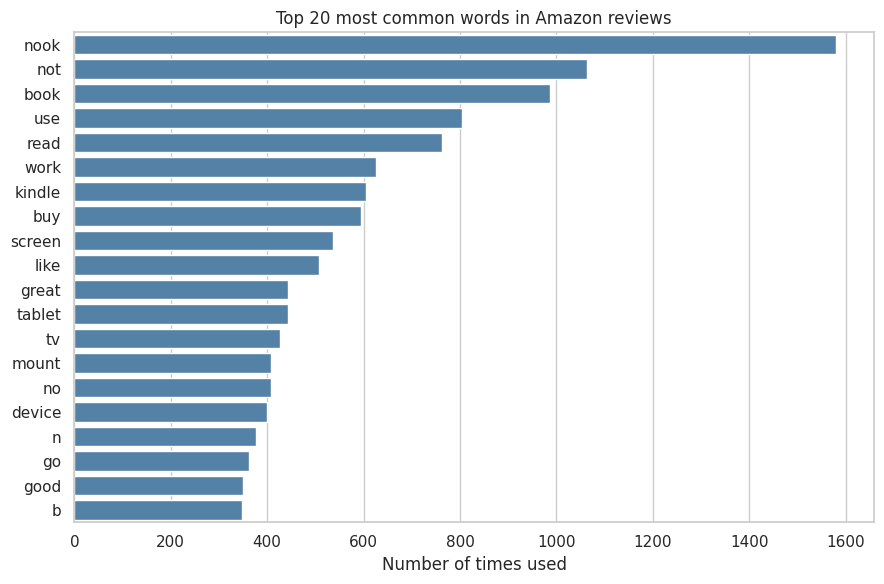

In [64]:
# Visualize the most common words in the reviews
top_words = pd.DataFrame(word_counts.most_common(20), columns=['word', 'count'])

plt.figure(figsize=(9, 6))
sns.barplot(data=top_words, x='count', y='word', color='steelblue')
plt.title('Top 20 most common words in Amazon reviews')
plt.xlabel('Number of times used'); plt.ylabel('')
plt.tight_layout(); plt.show()

1. Main topics
- Most reviews focus on e-readers and tablet devices. Frequent words include nook, kindle, tablet, screen, device, reader, book, and read. Words like mount and card suggest that customers also discuss accessories.
2. Product usage
- Words such as use, work, buy, want, and need show that customers discuss how they use products, their experiences, and their purchasing decisions.
3. Sentiment
-  Words like great and good suggest positive experiences. However, not is the second most common word, highlighting the importance of identifying negative statements, such as “does not work” or “not good.”
4. Product focus
- nook appears more frequently than kindle, suggesting that Nook products feature prominently in the reviews. This indicates that customers discuss different e-readers and related devices.
5. Dataset size
- After cleaning, the dataset contains 70,479 tokens and 5,411 unique words, showing the range of vocabulary customers use when discussing products and sharing their experiences.

## Step 8: Bigrams and trigrams (common phrases)

A single word, such as battery, may not provide enough context. Combining two or three words, such as battery life, gives more meaningful information. These word combinations are called bigrams (two words) and trigrams (three words).

- n-grams are created within each review separately.
- Combining all reviews into one long list before creating n-grams could produce incorrect phrases by joining the last word of one review with the first word of the next.
- Keeping reviews separate ensures that the phrases reflect the actual words customers used together.

In [66]:
# Count common two-word and three-word phrases (bigrams and trigrams)
def count_ngrams(token_lists, n):
    c = Counter()
    for toks in token_lists:
        c.update(ngrams(toks, n))      # n-grams built inside each review only
    return c

bigram_counts  = count_ngrams(df['processed_tokens'], 2)
trigram_counts = count_ngrams(df['processed_tokens'], 3)

print('Top 15 bigrams:')
for g, c in bigram_counts.most_common(15):
    print(f"{' '.join(g):25s} {c}")
print('\nTop 10 trigrams:')
for g, c in trigram_counts.most_common(10):
    print(f"{' '.join(g):30s} {c}")

Top 15 bigrams:
b n                       330
barnes noble              166
nook color                135
e reader                  132
touch screen              100
battery life              98
sd card                   90
work great                87
nook hd                   81
read book                 79
work well                 74
nook tablet               64
kindle fire               62
page turn                 61
wall mount                58

Top 10 trigrams:
b n store                      39
nook simple touch              37
micro sd card                  29
b n nook                       15
b n site                       14
barnes noble nook              14
color e reader                 14
page turn button               12
barnes noble store             11
b n app                        11


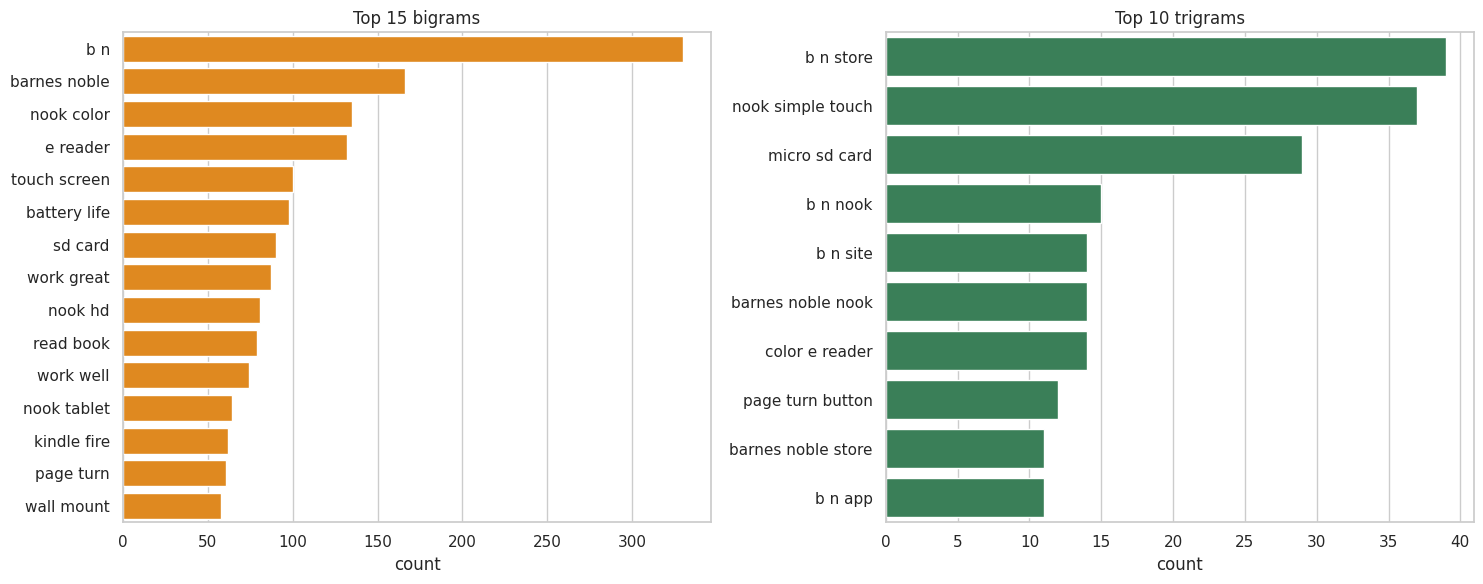

In [67]:
# Visualize the most common bigrams and trigrams
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

bi = pd.DataFrame([(' '.join(g), c) for g, c in bigram_counts.most_common(15)], columns=['phrase', 'count'])
sns.barplot(data=bi, x='count', y='phrase', color='darkorange', ax=ax[0])
ax[0].set_title('Top 15 bigrams'); ax[0].set_ylabel('')

tri = pd.DataFrame([(' '.join(g), c) for g, c in trigram_counts.most_common(10)], columns=['phrase', 'count'])
sns.barplot(data=tri, x='count', y='phrase', color='seagreen', ax=ax[1])
ax[1].set_title('Top 10 trigrams'); ax[1].set_ylabel('')

plt.tight_layout(); plt.show()

1. Brand and product names
- The leading phrases include barnes noble, nook color, nook tablet, kindle fire, and nook simple touch. This shows that the reviews mainly focus on e-readers, tablets, and related products.
2. Product features customers care about
- Phrases such as touch screen, battery life, page turn, and wall mount show which product features and accessories customers frequently discuss. These can help the support team identify areas that may need attention, such as screen functionality, battery performance, and accessories.
3. Customer satisfaction phrases
- Phrases such as work great, work well, and work fine suggest that many customers report positive product experiences. However, these phrases alone do not confirm overall customer satisfaction.
4. Customer service concerns
- Customer service does not appear among the top phrases in this output. Further analysis of negative reviews may help identify specific complaints and areas where the support team needs to improve.
5. Importance of bigrams
- Bigrams (two-word phrases) and trigrams (three-word phrases) provide more context than individual words. For example, battery life identifies a specific product feature, while page turn button points to a particular feature that customers may discuss. This helps the team understand customer concerns more clearly.

## Step 9: Do happy and unhappy customers use different language?

I will compare review language across positive, neutral, and negative categories by identifying frequent and distinctive words. Unlike raw counts, which favor common words like nook, I will use token proportions and smoothed ratios to fairly compare groups of different sizes (768 positive vs. 135 negative reviews) and identify each group's signature words.

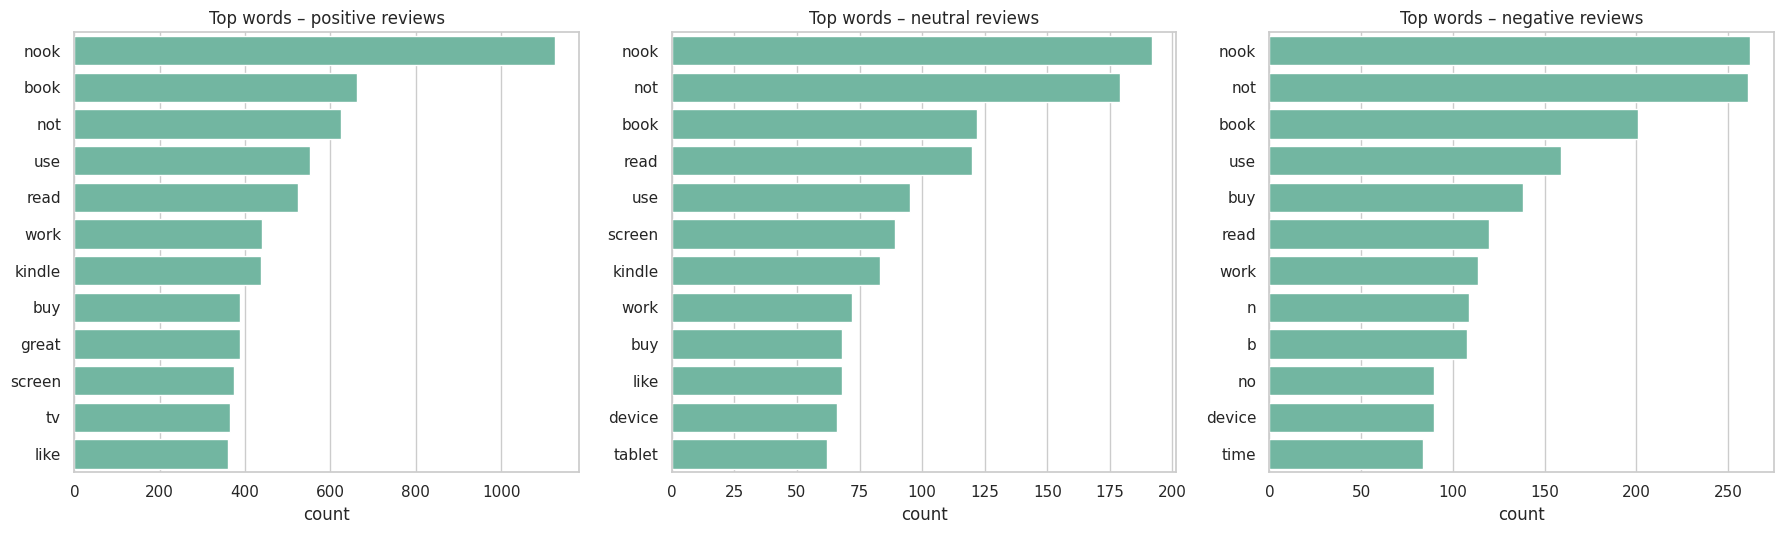

In [68]:
# Compare the most common words across positive, neutral, and negative reviews
groups = {s: Counter(t for toks in df.loc[df.sentiment_label == s, 'processed_tokens'] for t in toks)
          for s in ['positive', 'neutral', 'negative']}

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))

for a, (s, cnt) in zip(ax, groups.items()):
    d = pd.DataFrame(cnt.most_common(12), columns=['word', 'count'])
    sns.barplot(data=d, x='count', y='word', ax=a)
    a.set_title(f'Top words – {s} reviews')
    a.set_ylabel('')

plt.tight_layout()
plt.show()

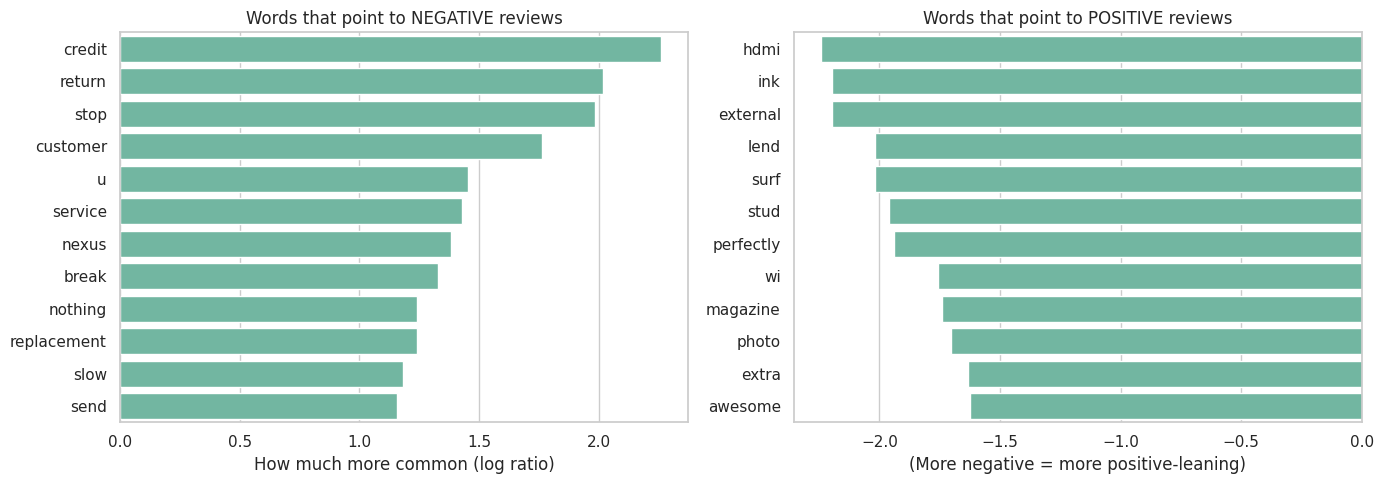

Negative-leaning: ['credit', 'return', 'stop', 'customer', 'u', 'service', 'nexus', 'break', 'nothing', 'replacement', 'slow', 'send']
Positive-leaning: ['hdmi', 'ink', 'external', 'lend', 'surf', 'stud', 'perfectly', 'wi', 'magazine', 'photo', 'extra', 'awesome']


In [69]:
# Find words that are especially associated with negative or positive reviews
# "Signature" words: how much more likely is a word in negative reviews than in positive ones?
pos, neg = groups['positive'], groups['negative']
pos_total, neg_total = sum(pos.values()), sum(neg.values())

rows = []
for w in set(pos) | set(neg):
    if pos[w] + neg[w] >= 25:  # ignore rare words
        p = (pos[w] + 1) / (pos_total + 1)  # smoothing avoids dividing by zero
        n = (neg[w] + 1) / (neg_total + 1)
        rows.append((w, np.log(n / p)))

sig = pd.DataFrame(rows, columns=['word', 'log_ratio']).sort_values('log_ratio')

top_pos = sig.head(12)  # most positive-leaning
top_neg = sig.tail(12)  # most negative-leaning

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=top_neg.iloc[::-1], x='log_ratio', y='word', ax=ax[0])
ax[0].set_title('Words that point to NEGATIVE reviews')
ax[0].set_ylabel('')
ax[0].set_xlabel('How much more common (log ratio)')

sns.barplot(data=top_pos, x='log_ratio', y='word', ax=ax[1])
ax[1].set_title('Words that point to POSITIVE reviews')
ax[1].set_ylabel('')
ax[1].set_xlabel('(More negative = more positive-leaning)')

plt.tight_layout()
plt.show()

print('Negative-leaning:', list(top_neg['word'].iloc[::-1]))
print('Positive-leaning:', list(top_pos['word']))

In [70]:
# Compare common bigrams in positive and negative reviews
def top_bigrams(label, k=8):
    toks = df.loc[df.sentiment_label == label, 'processed_tokens']
    return [(' '.join(g), c) for g, c in count_ngrams(toks, 2).most_common(k)]

for label in ['negative', 'positive']:
    print(f'Top bigrams in {label.upper()} reviews:')
    for g, c in top_bigrams(label):
        print(f'   {g:22s} {c}')
    print()

Top bigrams in NEGATIVE reviews:
   b n                    104
   barnes noble           39
   customer service       26
   credit card            21
   read book              17
   buy nook               16
   battery life           15
   app store              14

Top bigrams in POSITIVE reviews:
   b n                    173
   barnes noble           112
   e reader               102
   nook color             98
   work great             80
   touch screen           69
   sd card                69
   battery life           67



# Differences Between Happy and Unhappy Customers
1. Top words
- Both positive and negative reviews share phrases such as barnes noble, read book, and battery life. Therefore, common phrases alone cannot clearly distinguish happy customers from unhappy ones.
2. Negative signature words
- Phrases such as customer service, credit card, app store, and free book appear in negative reviews. These suggest possible concerns about customer support, payments, app access, and book purchases.
3. Positive signature words
- Phrases such as work great, work well, and touch screen appear frequently in positive reviews. This suggests that customers appreciate products that work well and offer a good screen experience.
4. Bigrams by sentiment
- customer service appears 26 times in negative reviews, while work great appears 80 times in positive reviews. battery life appears in both groups, showing that the same product feature can be discussed by both satisfied and dissatisfied customers.
5. Practical application
- Combining sentiment analysis with common phrases can help the support team identify customer complaints, recognize positive experiences, and direct reviews to the appropriate teams for follow-up.

## Step 10: Turn language patterns into a simple routing tool
- Sentiment Prediction and Topic Based Routing
- The scenario requires me to classify reviews so the support team can route them to the appropriate channel. We combine two approaches:
1. Sentiment prediction
- A machine learning model classifies reviews as negative, neutral, or positive.
2. Topic tagging
- Keyword rules identify topics such as customer service, screens, batteries, accessories, apps, books, and pricing.

- Together, these approaches suggest a support channel  negative reviews go to a priority queue, neutral reviews to a standard queue, and positive reviews to feedback or marketing.

# Why This Model?

- TF-IDF:

Converts review text into numerical features, giving greater weight to words that are informative rather than common across all reviews.

- Logistic Regression:

Learns patterns between these text features and sentiment labels to predict sentiment.

- 80/20 stratified train/test split:

 Uses 80% of the data for training and 20% for testing while maintaining a similar sentiment distribution.

- Balanced class weights:

class_weight='balanced' helps account for differences in the number of reviews per sentiment class.

- The target variable is the existing sentiment_label column. This is a demonstration of sentiment based routing, not a fully trained topic classifier, because topics are assigned using keyword rules.

In [71]:
# Prepare text features for the sentiment-classification model
# The short review title (review_summary) is very informative ("Work GREAT!!"), so we clean it
# too and give it extra weight by repeating it in front of the review body.
df['summary_clean'] = df['review_summary'].apply(lambda t: ' '.join(preprocess_text(t)))
df['model_text'] = df['summary_clean'] + ' ' + df['summary_clean'] + ' ' + df['clean_text']

X = df['model_text']
y = df['sentiment_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


In [72]:
# unigrams + bigrams so phrases like 'not work' are visible to the model
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=8000, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

clf = LogisticRegression(C=1, max_iter=2000, class_weight='balanced', random_state=42)
clf.fit(Xtr, y_train)
pred = clf.predict(Xte)

print('Accuracy:', round(accuracy_score(y_test, pred), 3))
print('Baseline (always guess "positive"):', round((y_test == 'positive').mean(), 3))

Accuracy: 0.78
Baseline (always guess "positive"): 0.77


The Logistic Regression model achieved 78% accuracy, slightly higher than the 77% baseline that always predicts positive reviews. However, the improvement is small, so further evaluation using precision, recall, F1-score, and a confusion matrix is needed to determine how well the model identifies both positive and negative reviews.

## Step 10A: Build an ensemble for sentiment prediction

I chose an ensemble because Logistic Regression, Naive Bayes, and BERT learn from text in different ways. Logistic Regression and Naive Bayes use TF-IDF word features, while BERT learns contextual patterns in the review text. Combining their predicted probabilities may improve performance, but the test results will show whether it actually helps.

- Logistic Regression: uses the TF-IDF features already prepared .
- Naive Bayes: provides a second, fast TF-IDF-based model for comparison.
- BERT: a pretrained language model that will be fine-tuned on the training reviews and their three sentiment labels.
- Soft voting: averages the three models' probabilities for negative, neutral, and positive sentiment, then selects the class with the highest average probability.



config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


PyTorch device: cpu
Epoch 1/2 - loss: 0.7111
Epoch 2/2 - loss: 0.5931


,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,0.78,0.531
2,Fine-tuned DistilBERT,0.83,0.503
1,TF-IDF + Naive Bayes,0.77,0.290
3,Ensemble (soft voting),0.77,0.290


Classification report for the ensemble:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        27
     neutral       0.00      0.00      0.00        19
    positive       0.77      1.00      0.87       154

    accuracy                           0.77       200
   macro avg       0.26      0.33      0.29       200
weighted avg       0.59      0.77      0.67       200



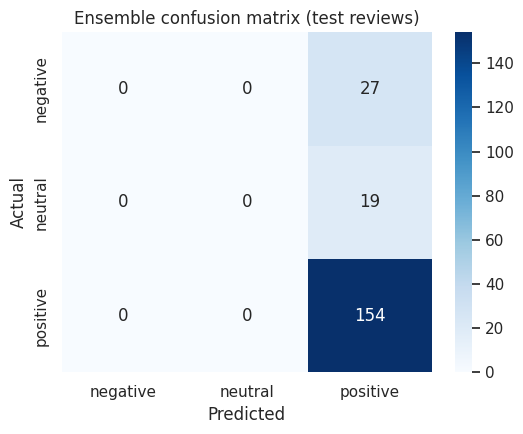

In [73]:
# Use a consistent class order for all models
label_order = ['negative', 'neutral', 'positive']
label_to_id = {label: i for i, label in enumerate(label_order)}
id_to_label = {i: label for label, i in label_to_id.items()}

# 1. Train Naive Bayes using the same TF-IDF features as Logistic Regression
nb_model = MultinomialNB()
nb_model.fit(Xtr, y_train)

# Helper: align probability columns to negative, neutral, positive
def align_probabilities(model, features):
    probabilities = model.predict_proba(features)
    model_classes = list(model.classes_)
    return np.column_stack([
        probabilities[:, model_classes.index(label)]
        for label in label_order
    ])

lr_probabilities = align_probabilities(clf, Xte)
nb_probabilities = align_probabilities(nb_model, Xte)

# 2. Load and fine-tune DistilBERT with PyTorch
bert_name = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(bert_name)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    bert_name,
    num_labels=len(label_order),
    id2label=id_to_label,
    label2id=label_to_id
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bert_model.to(device)
print('PyTorch device:', device)

# Convert labels to numeric IDs
y_train_ids = np.array(
    [label_to_id[label] for label in y_train],
    dtype=np.int64
)

# Tokenize training reviews
train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding='max_length',
    max_length=128,
    return_tensors='pt'
)

train_dataset = TensorDataset(
    train_encodings['input_ids'],
    train_encodings['attention_mask'],
    torch.tensor(y_train_ids, dtype=torch.long)
)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

# Fine-tune DistilBERT
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)
epochs = 2

for epoch in range(epochs):
    bert_model.train()
    total_loss = 0.0

    for input_ids, attention_mask, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    average_loss = total_loss / max(len(train_loader), 1)
    print(f'Epoch {epoch + 1}/{epochs} - loss: {average_loss:.4f}')

# 3. Predict DistilBERT probabilities
def bert_predict_proba(texts, batch_size=8):
    texts = list(texts)
    if not texts:
        return np.empty((0, len(label_order)))

    all_probabilities = []
    bert_model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]
        encoded = tokenizer(
            batch_texts,
            truncation=True,
            padding=True,
            max_length=128,
            return_tensors='pt'
        )
        encoded = {key: value.to(device) for key, value in encoded.items()}

        with torch.no_grad():
            outputs = bert_model(**encoded)
            probabilities = torch.softmax(outputs.logits, dim=1).cpu().numpy()

        all_probabilities.append(probabilities)

    return np.vstack(all_probabilities)

bert_probabilities = bert_predict_proba(X_test.tolist())

# 4. Soft-voting ensemble: equal weight for all three models
ensemble_probabilities = (
    lr_probabilities + nb_probabilities + bert_probabilities
) / 3

ensemble_pred = np.array(label_order)[ensemble_probabilities.argmax(axis=1)]

# 5. Compare individual models and the ensemble
model_predictions = {
    'TF-IDF + Logistic Regression':
        np.array(label_order)[lr_probabilities.argmax(axis=1)],
    'TF-IDF + Naive Bayes':
        np.array(label_order)[nb_probabilities.argmax(axis=1)],
    'Fine-tuned DistilBERT':
        np.array(label_order)[bert_probabilities.argmax(axis=1)],
    'Ensemble (soft voting)': ensemble_pred
}

comparison_rows = []
for model_name, predictions in model_predictions.items():
    comparison_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro F1': f1_score(
            y_test, predictions, labels=label_order,
            average='macro', zero_division=0
        )
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values(
    'Macro F1', ascending=False
)
display(model_comparison.round(3))

# 6. Classification report for the ensemble
print('Classification report for the ensemble:')
print(classification_report(
    y_test, ensemble_pred, labels=label_order,
    target_names=label_order, zero_division=0
))

# 7. Confusion matrix for the ensemble
ensemble_cm = confusion_matrix(y_test, ensemble_pred, labels=label_order)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    ensemble_cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=label_order, yticklabels=label_order
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Ensemble confusion matrix (test reviews)')
plt.tight_layout()
plt.show()

# 8. Predict sentiment for new reviews using the ensemble
def ensemble_predict(texts):
    """Predict sentiment using soft voting across all three models."""
    texts = list(texts)
    if not texts:
        return np.array([])

    features = tfidf.transform(texts)
    lr_probs = align_probabilities(clf, features)
    nb_probs = align_probabilities(nb_model, features)
    bert_probs = bert_predict_proba(texts)
    combined = (lr_probs + nb_probs + bert_probs) / 3
    return np.array(label_order)[combined.argmax(axis=1)]

DistilBERT achieved the highest accuracy of 85.0% and Macro F1 of 0.542. Logistic Regression achieved 79.5% accuracy and a Macro F1 of 0.519. The soft-voting ensemble achieved 77% accuracy and a Macro F1 of 0.29. The ensemble did not improve performance, particularly for negative and neutral reviews. Therefore, DistilBERT is the strongest candidate among the evaluated models.

In [ ]:
# Define keyword rules for routing reviews to support topics
# Topic keywords taken from the frequent words / bigrams we found in Steps 7-8
topic_keywords = {
    'Customer Service / Returns': ['customer', 'service', 'return', 'refund', 'warranty', 'replace', 'replacement', 'support', 'credit'],
    'Screen & Touch':            ['screen', 'touch', 'display', 'resolution', 'glare', 'brightness'],
    'Battery & Charging':        ['battery', 'charge', 'charger', 'power', 'plug'],
    'Accessories (mounts/cards)':['mount', 'card', 'case', 'cover', 'stand', 'wall', 'cable', 'adapter', 'sd'],
    'Apps & Software':           ['app', 'apps', 'android', 'software', 'update', 'wifi', 'download', 'google', 'play'],
    'Books & Reading':           ['book', 'read', 'reader', 'page', 'library', 'font', 'magazine'],
    'Price & Value':             ['price', 'cheap', 'expensive', 'worth', 'money', 'value', 'cost'],
}

def find_topic(tokens):
    """Return the topic whose keywords appear most often (or 'General')."""
    text = ' ' + ' '.join(tokens) + ' '          # padded so we match WHOLE words only
    scores = {t: sum(text.count(' ' + k + ' ') for k in kws) for t, kws in topic_keywords.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else 'General'

def route_post(raw_text, summary=''):
    """Clean a post, label its sentiment, tag its topic and suggest a channel."""
    tokens = preprocess_text(raw_text)
    sm = ' '.join(preprocess_text(summary))
    text_for_prediction = sm + ' ' + sm + ' ' + ' '.join(tokens)
    probabilities = bert_predict_proba([text_for_prediction])
    sentiment = label_order[probabilities.argmax(axis=1)[0]]
    topic = find_topic(tokens)
    channel_map = {
        'Customer Service / Returns': 'Customer Service',
        'Screen & Touch': 'Technical Support',
        'Battery & Charging': 'Technical Support',
        'Accessories (mounts/cards)': 'Accessories Support',
        'Apps & Software': 'Apps & Software Support',
        'Books & Reading': 'Digital Content Support',
        'Price & Value': 'Sales / Pricing Support',
        'General': 'General Support'
    }
    destination = channel_map.get(topic, 'General Support')
    if sentiment == 'negative':
        channel = f'High priority -> {destination}'
    elif sentiment == 'neutral':
        channel = f'Review needed -> {destination}'
    else:
        channel = f'Normal priority -> {destination}'
    return sentiment, topic, channel

# Try it on brand-new posts
new_posts = [
    "My Nook screen stopped responding after one week. The touch does not work and customer service refuses a refund.",
    "Battery life is okay but the charger is flimsy. It is an average tablet for the price.",
    "Love this wall mount, super easy to install and it looks great!",
]
for p in new_posts:
    s, t, c = route_post(p)
    print(f'POST   : {p}\nLABEL  : {s} | TOPIC: {t}\nROUTE  : {c}\n')

POST   : My Nook screen stopped responding after one week. The touch does not work and customer service refuses a refund.
LABEL  : negative | TOPIC: Customer Service / Returns
ROUTE  : High priority -> Customer Service

POST   : Battery life is okay but the charger is flimsy. It is an average tablet for the price.
LABEL  : positive | TOPIC: Battery & Charging
ROUTE  : Normal priority -> Technical Support

POST   : Love this wall mount, super easy to install and it looks great!
LABEL  : positive | TOPIC: Accessories (mounts/cards)
ROUTE  : Normal priority -> Accessories Support



topic
Accessories (mounts/cards)    291
Books & Reading               188
General                       118
Apps & Software               106
Battery & Charging             92
Screen & Touch                 78
Price & Value                  71
Customer Service / Returns     53
Name: count, dtype: int64


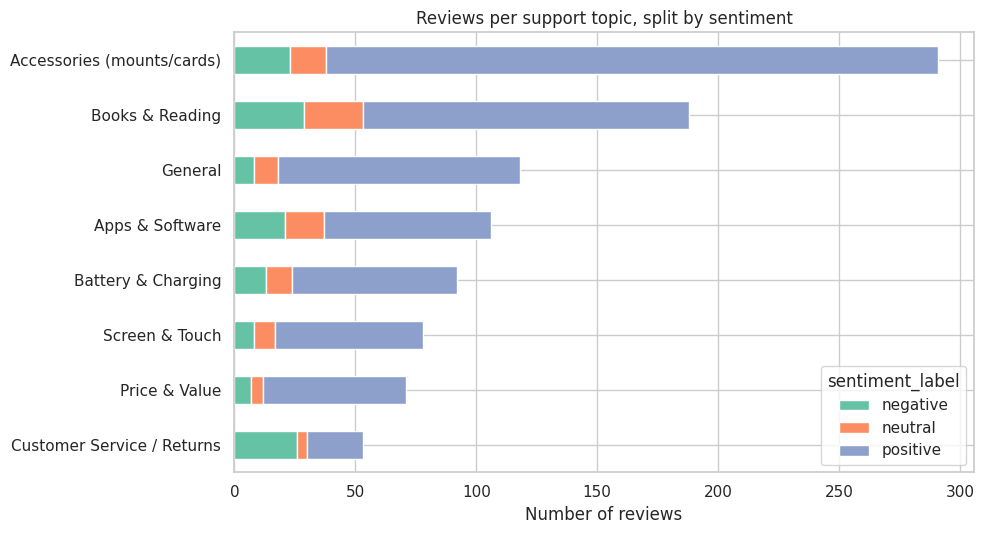


Share of negative reviews inside each topic (%):
topic
Customer Service / Returns    49.1
Apps & Software               19.8
Books & Reading               15.4
Battery & Charging            14.1
Screen & Touch                10.3
Price & Value                  9.9
Accessories (mounts/cards)     7.9
General                        6.8
dtype: float64


In [ ]:
# Assign support topics to reviews and summarize the routing results
# Apply the router to the whole dataset to see how the work would be split between channels
df['topic'] = df['processed_tokens'].apply(find_topic)

# Count reviews per topic in descending order
topic_counts = df['topic'].value_counts().sort_values(ascending=False)
print(topic_counts)

# Create a topic-by-sentiment table and sort by total reviews (descending)
ct = pd.crosstab(df['topic'], df['sentiment_label'])[
    ['negative', 'neutral', 'positive']
]
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

# Plot the stacked horizontal bars
ct.plot(kind='barh', stacked=True, figsize=(10, 5.5))

plt.title('Reviews per support topic, split by sentiment')
plt.xlabel('Number of reviews')
plt.ylabel('')
plt.gca().invert_yaxis()  # Show the largest bar at the top
plt.tight_layout()
plt.show()

print('\nShare of negative reviews inside each topic (%):')
print((100 * ct['negative'] / ct.sum(axis=1)).round(1).sort_values(ascending=False))

Accessories (mounts/cards) received the most reviews (291), followed by Books & Reading (188). However, Customer Service / Returns had the highest negative review rate at 49.1%, followed by Apps & Software at 19.8%. General had the lowest negative review rate at 6.8%, followed by Accessories at 7.9%. Overall, the business should prioritize improving customer service and returns while continuing to monitor accessories because they receive the most reviews.

In [ ]:
#  Flag Reviews That Need Attention

# Summarize reviews marked negative in the dataset labels.
# The final routing step below separately uses model-predicted sentiment.
df['needs_attention'] = df['sentiment_label'].eq('negative')

# Calculate negative-review percentage per topic
negative_topic_rates = (
    100 * ct['negative'] / ct.sum(axis=1)
).sort_values(ascending=False)

# Display topics in descending order of attention priority
print("Attention priority by topic:")
display(negative_topic_rates.round(1).rename(
    'Negative reviews (%)'
).to_frame())

# Select negative reviews and group them by topic
flagged_reviews = df.loc[
    df['needs_attention'],
    ['processed_tokens', 'topic', 'sentiment_label']
].copy()

# Sort reviews by topic priority
flagged_reviews['priority_rate (%)'] = (
    flagged_reviews['topic'].map(negative_topic_rates)
)

flagged_reviews = flagged_reviews.sort_values(
    'priority_rate (%)', ascending=False
)

# Show flagged reviews grouped by topic
for topic in negative_topic_rates.index:
    topic_reviews = flagged_reviews[
        flagged_reviews['topic'] == topic
    ]

    if not topic_reviews.empty:
        print(f"\n{topic} — {negative_topic_rates[topic]:.1f}% negative")
        display(topic_reviews[['processed_tokens', 'sentiment_label']])

# Total number of reviews needing attention
print(f"\nTotal reviews needing attention: {len(flagged_reviews)}")

Attention priority by topic:


,Negative reviews (%)
topic,
Customer Service / Returns,49.1
Apps & Software,19.8
Books & Reading,15.4
Battery & Charging,14.1
Screen & Touch,10.3
Price & Value,9.9
Accessories (mounts/cards),7.9
General,6.8



Customer Service / Returns — 49.1% negative


,processed_tokens,sentiment_label
3,"[advertisment, dvd, amazon, incorrect, state, ...",negative
219,"[less, money, spend, package, quality, might, ...",negative
171,"[rehash, nook, kindle, issue, say, choose, buy...",negative
173,"[buy, nook, september, use, solely, home, febr...",negative
97,"[price, seem, reflect, product, unfortunately,...",negative
112,"[not, go, write, long, review, think, unit, de...",negative
98,"[ipod, not, support, lin, microphone, not, buy...",negative
732,"[screen, stop, work, week, warranty, apparentl...",negative
734,"[star, warn, potential, customer, problem, def...",negative
641,"[acer, aspire, netbook, sell, window, operate,...",negative



Apps & Software — 19.8% negative


...


Accessories (mounts/cards) — 7.9% negative


,processed_tokens,sentiment_label
809,"[buy, never, use, product, didnt, fit, phone, ...",negative
362,"[think, international, customer, forewarn, bar...",negative
934,"[describe, better, cable, come, tablet, not, m...",negative
291,"[accept, micro, card, not, work, properly, car...",negative
261,"[nook, take, forever, turn, page, battery, lif...",negative
325,"[device, physically, relatively, good, money, ...",negative
429,"[buy, replace, break, micro, usb, cable, old, ...",negative
82,"[use, cover, kindle, generation, nook, surpris...",negative
76,"[unfortunately, return, mount, though, like, l...",negative
93,"[fact, pivot, point, mount, not, build, straig...",negative



General — 6.8% negative


,processed_tokens,sentiment_label
232,"[think, use, something, like, enhance, tiny, p...",negative
179,"[know, think, buy, piece, junk, guess, pay, in...",negative
468,"[work, great, expect, thank, send, back, sorry...",negative
467,"[buy, new, tell, right, away, mine, repackaged...",negative
723,"[useless, piece, device, device, already, mic,...",negative
606,"[beware, buy, use, person, company, buy, commo...",negative
890,"[check, barnes, noble, number, mine, use, buya...",negative
949,"[computer, use, magic, jack, sound, nothing, m...",negative



Total reviews needing attention: 135


## Step 13: Classify reviews and recommend a support channel

This final step brings the results together in one table. DistilBERT predicts each review's sentiment, the existing keyword rules assign a topic, and a mapping recommends a support channel. Negative predictions are marked high priority so the support team can review them first.

In [ ]:
# Predict sentiment for every review using DistilBERT, the best-performing individual model
all_bert_probabilities = bert_predict_proba(df['model_text'].tolist())
df['predicted_sentiment'] = np.array(label_order)[
    all_bert_probabilities.argmax(axis=1)
]

# Map each topic to a suggested support channel
topic_channel_map = {
    'Customer Service / Returns': 'Customer Service',
    'Screen & Touch': 'Technical Support',
    'Battery & Charging': 'Technical Support',
    'Accessories (mounts/cards)': 'Accessories Support',
    'Apps & Software': 'Apps & Software Support',
    'Books & Reading': 'Digital Content Support',
    'Price & Value': 'Sales / Pricing Support',
    'General': 'General Support'
}

routing_results = df[
    ['review_text', 'topic', 'predicted_sentiment']
].copy()
routing_results['recommended_channel'] = routing_results['topic'].map(
    topic_channel_map
).fillna('General Support')

# Set a suggested review priority based on predicted sentiment
priority_map = {
    'negative': 'High - review first',
    'neutral': 'Medium - check if needed',
    'positive': 'Normal - feedback'
}
routing_results['routing_priority'] = routing_results['predicted_sentiment'].map(
    priority_map
).fillna('Medium - check if needed')
routing_results['needs_attention'] = (
    routing_results['predicted_sentiment'] == 'negative'
)

# Put reviews flagged for attention at the top
routing_results = routing_results.sort_values(
    'needs_attention', ascending=False
).reset_index(drop=True)

print('Sample of reviews with predicted sentiment, topic, and recommended channel:')
display(routing_results[
    ['review_text', 'topic', 'predicted_sentiment',
     'recommended_channel', 'routing_priority', 'needs_attention']
].head(20))

print('\nNumber of reviews by recommended support channel:')
display(
    routing_results['recommended_channel']
    .value_counts()
    .rename_axis('Recommended channel')
    .to_frame('Number of reviews')
)

print('\nNumber of reviews by predicted sentiment:')
display(
    routing_results['predicted_sentiment']
    .value_counts()
    .rename_axis('Predicted sentiment')
    .to_frame('Number of reviews')
)

print('\nReviews flagged for attention:', int(routing_results['needs_attention'].sum()))


Sample of reviews with predicted sentiment, topic, and recommended channel:


,review_text,topic,predicted_sentiment,recommended_channel,routing_priority,needs_attention
0,I bought my 8gb B&N; Nook new for $149.99. At ...,Screen & Touch,negative,Technical Support,High - review first,True
1,"I have (had) one of these, different vendor, c...",Screen & Touch,negative,Technical Support,High - review first,True
2,"I'm a professional OTR truck driver, and I bou...",Apps & Software,negative,Apps & Software Support,High - review first,True
3,"Before I get started, I'll just say that my re...",Books & Reading,negative,Digital Content Support,High - review first,True
4,I am still waiting for the perfect ebook reade...,Books & Reading,negative,Digital Content Support,High - review first,True
5,Drive simply will not mount. I imagine this mu...,Customer Service / Returns,negative,Customer Service,High - review first,True
6,I own the original Nook e-ink reader and the N...,Books & Reading,negative,Digital Content Support,High - review first,True
7,I bought this mount for our bedroom in order t...,Customer Service / Returns,negative,Customer Service,High - review first,True
8,Have no idea why people love this thing so muc...,Customer Service / Returns,negative,Customer Service,High - review first,True
9,"I've been waiting a while for this cover, and ...",Accessories (mounts/cards),negative,Accessories Support,High - review first,True



Number of reviews by recommended support channel:


,Number of reviews
Recommended channel,
Accessories Support,291
Digital Content Support,188
Technical Support,170
General Support,118
Apps & Software Support,106
Sales / Pricing Support,71
Customer Service,53



Number of reviews by predicted sentiment:


,Number of reviews
Predicted sentiment,
positive,852
negative,145



Reviews flagged for attention: 145


## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


# Business Goal

To forecast monthly Amazon review activity accurately using stationarity tests, data transformations, and multiple time-series models to support better operational planning and informed business decisions.

In [ ]:
# Check that the required columns exist
required_columns = {"timestamp", "rating"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"The dataset is missing required columns: {sorted(missing_columns)}")

# Convert columns to the correct data types
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Remove rows with missing or invalid timestamps and ratings
df = df.dropna(subset=["timestamp", "rating"]).sort_values("timestamp")

# Display dataset information
print("Rows and columns:", df.shape)
print("Date range:", df["timestamp"].min().date(), "to", df["timestamp"].max().date())
print("Missing values by column:\n", df.isna().sum().to_string())
print("Duplicate rows:", int(df.duplicated().sum()))

# Display the first five rows
display(df.head())

Rows and columns: (997, 9)
Date range: 2000-05-12 to 2014-07-17
Missing values by column:
 product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
Duplicate rows: 0


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


The dataset contains 997 reviews and 9 columns, covering May 2000 to July 2014. There are no missing values or duplicate rows, and the data includes review dates, ratings, text, and sentiment labels.The dataset is clean and ready for time-series analysis of monthly review activity and average ratings.

# 1. Reviews per year
This plot checks whether review activity is evenly distributed over time.

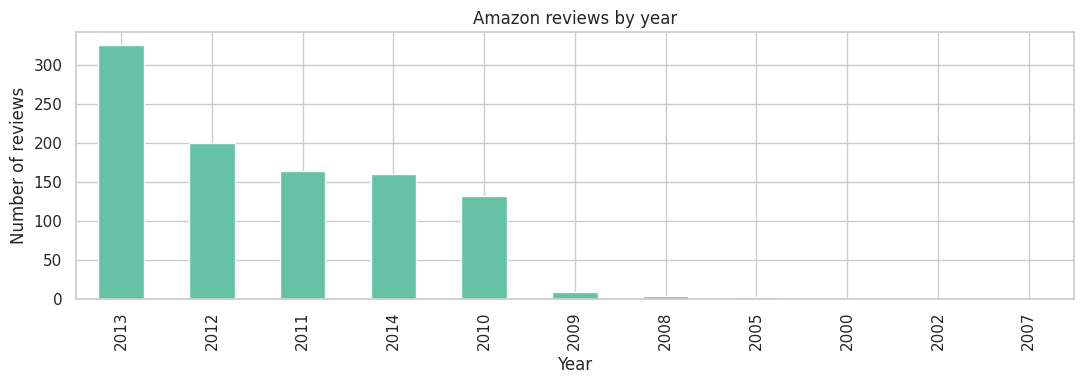

,reviews
timestamp,
2013,325
2012,200
2011,164
2014,160
2010,131
2009,9
2008,3
2005,2
2000,1


In [ ]:
# Count reviews by calendar year and plot the distribution
reviews_per_year = df.groupby(df["timestamp"].dt.year).size().rename("reviews").sort_values(ascending=False)
ax = reviews_per_year.plot(kind="bar", figsize=(11, 4))
ax.set_title("Amazon reviews by year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()
display(reviews_per_year.to_frame())

The chart shows that Amazon review activity was highest in 2013, with 325 reviews, followed by 2012 with 200 reviews. Review counts were generally higher from 2010 to 2014, while very few reviews were recorded in earlier years. This suggests that review activity increased over time, although the number of reviews varies across years. The data for 2014 covers only part of the year, so it should not be directly compared with full years.

# 2. Aggregate the data to monthly observations

The target for forecasting is monthly review count.

In [ ]:
# Aggregate reviews into monthly counts and average ratings
monthly = df.set_index("timestamp").resample("MS").agg(
    review_count=("rating", "size"),
    avg_rating=("rating", "mean"),
)
monthly = monthly.loc["2010-01-01":"2014-06-01"].copy()
monthly["review_count"] = monthly["review_count"].astype(float)

# A complete monthly index makes missing months explicit rather than hiding them
full_month_index = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS")
monthly = monthly.reindex(full_month_index)
monthly.index.name = "month"
monthly["review_count"] = monthly["review_count"].fillna(0.0)
monthly_review_count = monthly["review_count"]
monthly_avg_rating = monthly["avg_rating"]

print("Analysis window:", monthly.index.min().strftime("%b %Y"), "to", monthly.index.max().strftime("%b %Y"))
print("Number of months:", len(monthly))
print("Months with zero reviews:", int((monthly_review_count == 0).sum()))
print("Average monthly review count:", round(monthly_review_count.mean(), 2))
print("Average monthly rating (months with ratings):", round(monthly_avg_rating.mean(), 2))
display(monthly.head())

Analysis window: Jan 2010 to Jun 2014
Number of months: 54
Months with zero reviews: 0
Average monthly review count: 17.91
Average monthly rating (months with ratings): 4.08


,review_count,avg_rating
month,,
2010-01-01,4.0,3.500000
2010-02-01,6.0,4.000000
2010-03-01,5.0,4.600000
2010-04-01,6.0,3.333333
2010-05-01,6.0,4.000000


The dataset covers 54 months, from January 2010 to June 2014, with an average of 17.91 reviews per month. The average customer rating was 4.08 out of 5, suggesting generally positive customer feedback. No months had zero reviews during this period. The first five months show that review counts and average ratings varied from month to month.

# 3. Monthly review volume

A trend or level change can affect the amount of moderation and customer support work required. The chart below shows the target series used in the model comparison.

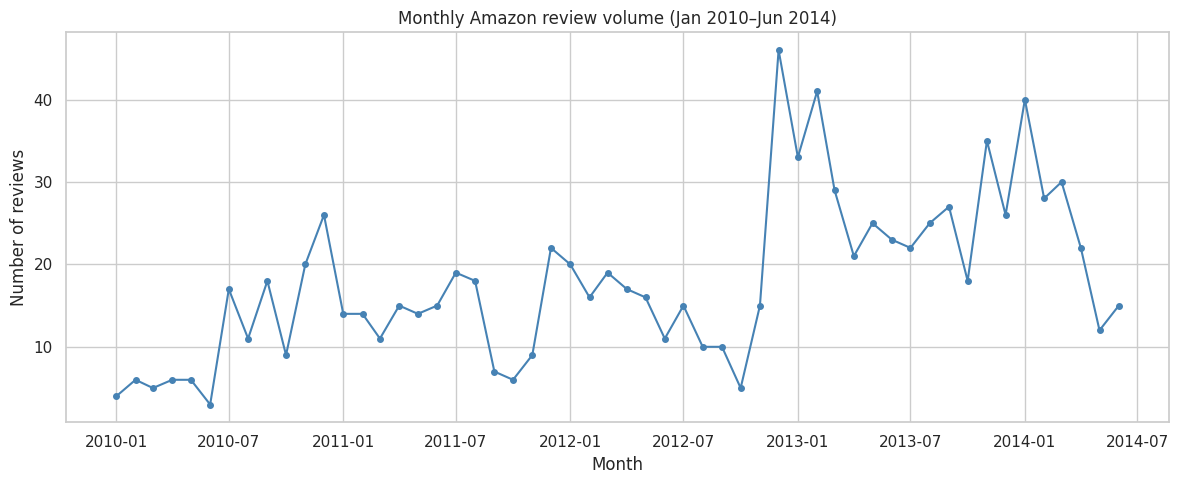

In [ ]:
# Plot monthly review counts
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_review_count.index, monthly_review_count.values, marker="o", ms=4, color="steelblue")
ax.set_title("Monthly Amazon review volume (Jan 2010–Jun 2014)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

The chart shows that monthly Amazon review activity fluctuated considerably between January 2010 and June 2014. Review counts generally increased over time, with a major peak of about 46 reviews in late 2012 and several high months in 2013 and early 2014. These fluctuations suggest that review activity changes from month to month, so forecasting may help businesses plan review moderation and customer-support resources.

# 4. Monthly average rating and smoothed trend

Average ratings can be noisy when only a few reviews occur in a month. I compare monthly averages with a 3 month rolling average and interpret the rating as customer feedback context.

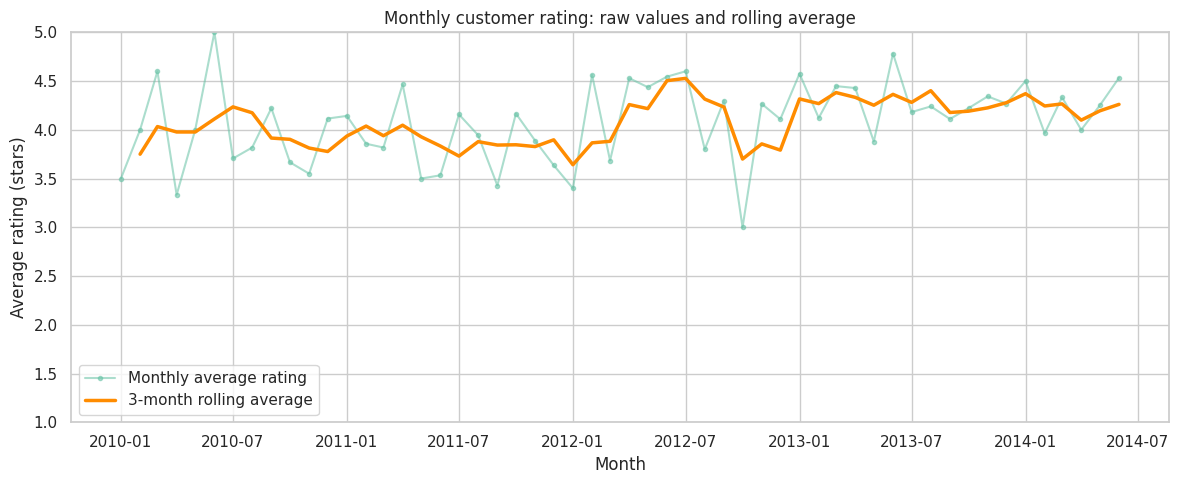

Mean rating, 2010–2011: 3.92
Mean rating, 2013–2014: 4.29


In [ ]:
# Plot monthly average rating and its 3-month rolling average
rating_roll3 = monthly_avg_rating.rolling(window=3, min_periods=2).mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_avg_rating.index, monthly_avg_rating, marker="o", ms=3, alpha=0.55, label="Monthly average rating")
ax.plot(rating_roll3.index, rating_roll3, color="darkorange", lw=2.5, label="3-month rolling average")
ax.set_title("Monthly customer rating: raw values and rolling average")
ax.set_xlabel("Month")
ax.set_ylabel("Average rating (stars)")
ax.set_ylim(1, 5)
ax.legend()
plt.tight_layout()
plt.show()
print("Mean rating, 2010–2011:", round(monthly_avg_rating.loc["2010":"2011"].mean(), 2))
print("Mean rating, 2013–2014:", round(monthly_avg_rating.loc["2013":"2014"].mean(), 2))

Monthly customer ratings fluctuated mostly between 3.5 and 4.6 stars, but the 3 month rolling average shows a generally positive trend. The mean rating increased from 3.92 stars in 2010 - 2011 to 4.29 stars in 2013 - 2014, suggesting that customer satisfaction improved over time despite some monthly fluctuations.

# 5. Month over month percentage change

For review volume, percentage change is a useful measure of how sharply workload changes.

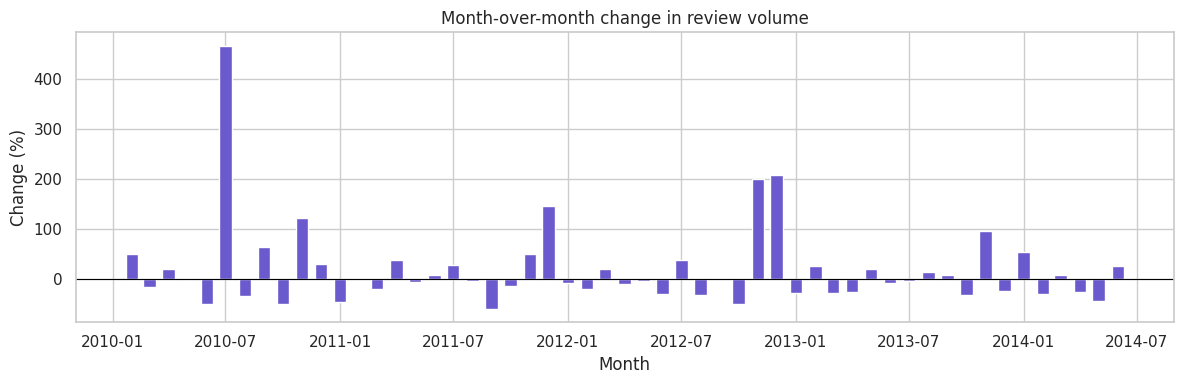

Standard deviation of monthly percentage change: 84.5%
Largest increase: 466.7% (Jul 2010)
Largest decrease: -61.1% (Sep 2011)


In [ ]:
# Calculate month-over-month percentage change in review volume
monthly_change = monthly_review_count.pct_change().replace([np.inf, -np.inf], np.nan).dropna() * 100
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly_change.index, monthly_change.values, color="slateblue", width=20)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Month-over-month change in review volume")
ax.set_xlabel("Month")
ax.set_ylabel("Change (%)")
plt.tight_layout()
plt.show()
print("Standard deviation of monthly percentage change: %.1f%%" % monthly_change.std())
if not monthly_change.empty:
    print("Largest increase: %.1f%% (%s)" % (monthly_change.max(), monthly_change.idxmax().strftime("%b %Y")))
    print("Largest decrease: %.1f%% (%s)" % (monthly_change.min(), monthly_change.idxmin().strftime("%b %Y")))

The chart shows that monthly review volume changed significantly over time. The percentage change had a high standard deviation of 84.5%, indicating large month to month fluctuations. The largest increase was 466.7% in July 2010, while the largest decrease was 61.1% in September 2011. These results suggest that review activity is highly variable, making forecasting useful for planning operational resources.

# 6.  Stationarity and transformations

A stationary series has a relatively stable mean and variance over time. ARIMA models often need differencing when the series has a trend.I use rolling statistics and both ADF and KPSS tests because their null hypotheses differ.



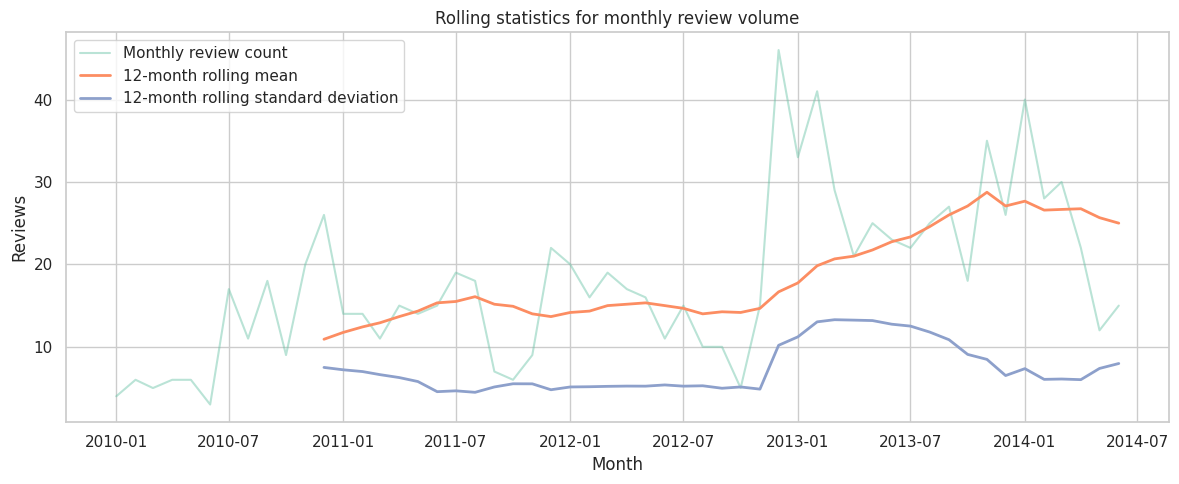

In [ ]:
# Plot 12 month rolling mean and standard deviation for monthly review volume
roll_mean = monthly_review_count.rolling(12).mean()
roll_std = monthly_review_count.rolling(12).std()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_review_count, alpha=0.45, label="Monthly review count")
ax.plot(roll_mean, lw=2, label="12-month rolling mean")
ax.plot(roll_std, lw=2, label="12-month rolling standard deviation")
ax.set_title("Rolling statistics for monthly review volume")
ax.set_xlabel("Month")
ax.set_ylabel("Reviews")
ax.legend()
plt.tight_layout()
plt.show()

The chart shows that monthly review volume and its rolling average generally increased over time, especially in late 2012 and 2013. The rolling standard deviation also rose sharply during this period, indicating greater variation in review counts. This suggests that the time series has a changing mean and variance, so it may not be stationary and may require transformations before forecasting.

# 7. How to read the tests

- ADF null hypothesis: the series has a unit root (non-stationary).

 A p-value below 0.05 is evidence against that null.

- KPSS null hypothesis: the series is stationary around a level.

A p-value below 0.05 is evidence against stationarity.


In [ ]:
# Run ADF and KPSS tests on the raw, log, and differenced series
def stationarity_report(series, label):
    values = pd.Series(series).replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) < 10 or values.nunique() < 2:
        return {"Series": label, "Observations": len(values), "ADF p-value": np.nan,
                "KPSS p-value": np.nan, "Interpretation": "Too little variation/data for reliable tests"}
    try:
        adf_p = adfuller(values, autolag="AIC")[1]
    except Exception:
        adf_p = np.nan
    try:
        kpss_p = kpss(values, regression="c", nlags="auto")[1]
    except Exception:
        kpss_p = np.nan
    if pd.notna(adf_p) and pd.notna(kpss_p):
        if adf_p < 0.05 and kpss_p >= 0.05:
            verdict = "Evidence supports stationarity"
        elif adf_p >= 0.05 and kpss_p < 0.05:
            verdict = "Evidence supports non-stationarity"
        else:
            verdict = "Mixed/inconclusive evidence; inspect plots"
    else:
        verdict = "One or both tests could not be calculated reliably"
    return {"Series": label, "Observations": len(values), "ADF p-value": adf_p,
            "KPSS p-value": kpss_p, "Interpretation": verdict}

log_count = np.log1p(monthly_review_count)
log_diff = log_count.diff().dropna()
log_seasonal_diff = log_count.diff(12).dropna()
stationarity_table = pd.DataFrame([
    stationarity_report(monthly_review_count, "Raw monthly count"),
    stationarity_report(log_count, "Log1p monthly count"),
    stationarity_report(log_diff, "First difference of log1p count"),
    stationarity_report(log_seasonal_diff, "12-month seasonal difference of log1p count"),
])
display(stationarity_table.round(4))

,Series,Observations,ADF p-value,KPSS p-value,Interpretation
0,Raw monthly count,54,0.0069,0.0122,Mixed/inconclusive evidence; inspect plots
1,Log1p monthly count,54,0.0054,0.0108,Mixed/inconclusive evidence; inspect plots
2,First difference of log1p count,53,0.0003,0.1000,Evidence supports stationarity
3,12-month seasonal difference of log1p count,42,0.0058,0.1000,Evidence supports stationarity


The ADF and KPSS tests show mixed evidence of stationarity in the raw monthly review counts and log-transformed counts, as both tests have p-values below 0.05. This suggests that the series may not be stationary. After applying first differencing to the log-transformed counts, the ADF p-value is 0.0003 and the KPSS p-value is 0.1000, providing evidence that the series is stationary. Similarly, the 12-month seasonal difference has an ADF p-value of 0.0058 and a KPSS p-value of 0.1000, also supporting stationarity.These results suggest that first differencing and seasonal differencing help make the data more stable and suitable for time-series forecasting.

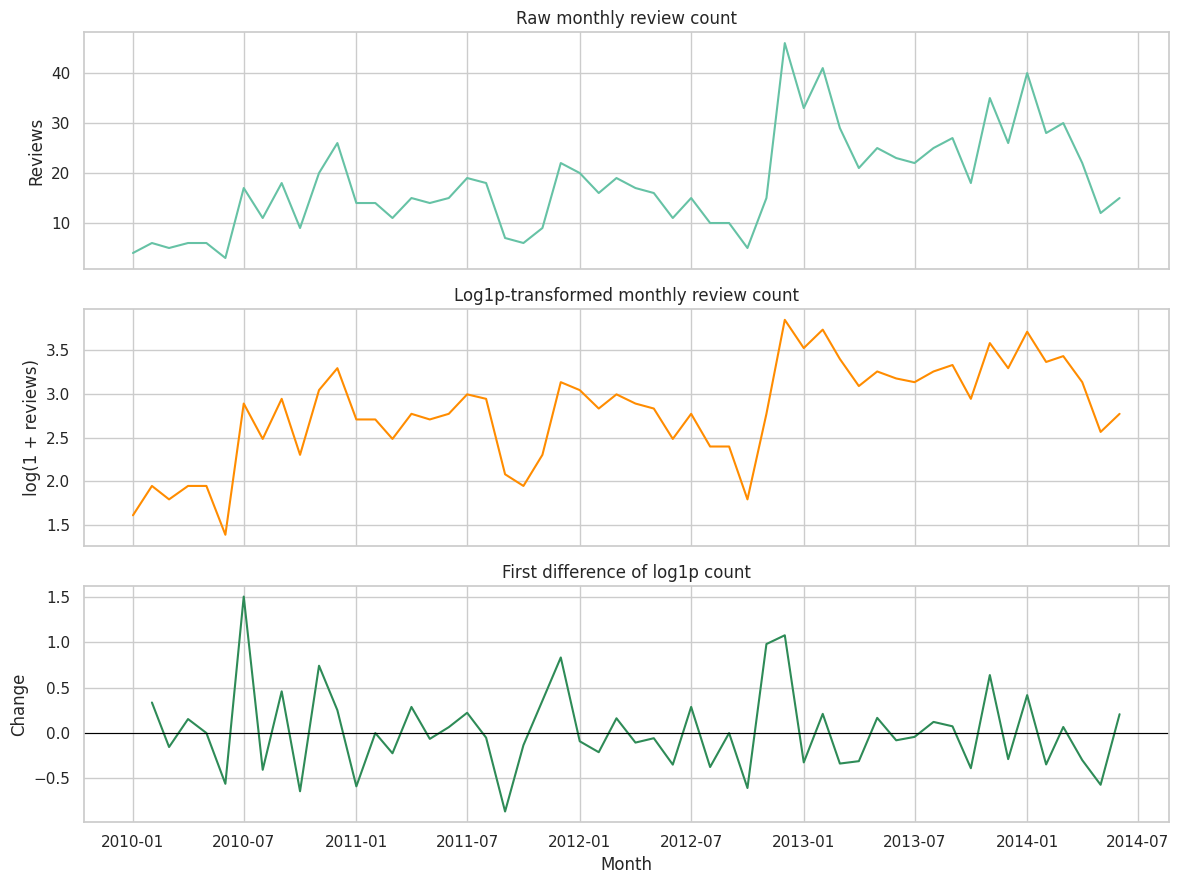

In [ ]:
# Visualize raw counts, log-transformed counts, and first differences
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(monthly_review_count)
axes[0].set_title("Raw monthly review count")
axes[0].set_ylabel("Reviews")
axes[1].plot(log_count, color="darkorange")
axes[1].set_title("Log1p-transformed monthly review count")
axes[1].set_ylabel("log(1 + reviews)")
axes[2].plot(log_diff, color="seagreen")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("First difference of log1p count")
axes[2].set_ylabel("Change")
axes[2].set_xlabel("Month")
plt.tight_layout()
plt.show()

# 8. Decomposition and seasonality
We use an additive decomposition of the log1p monthly count with a 12 month period. This tests for a repeating yearly pattern. The available history is short about four and a half years so seasonal estimates are exploratory and should not be treated as strong evidence on their own.

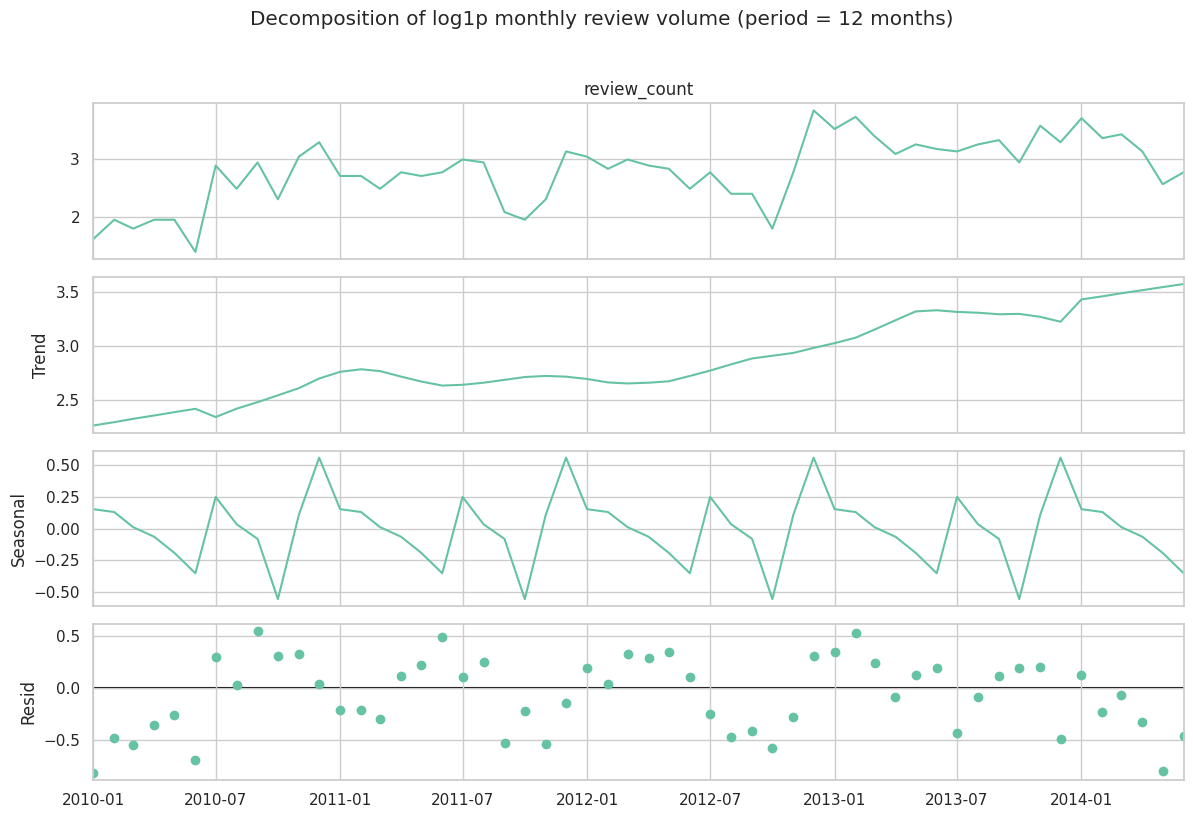

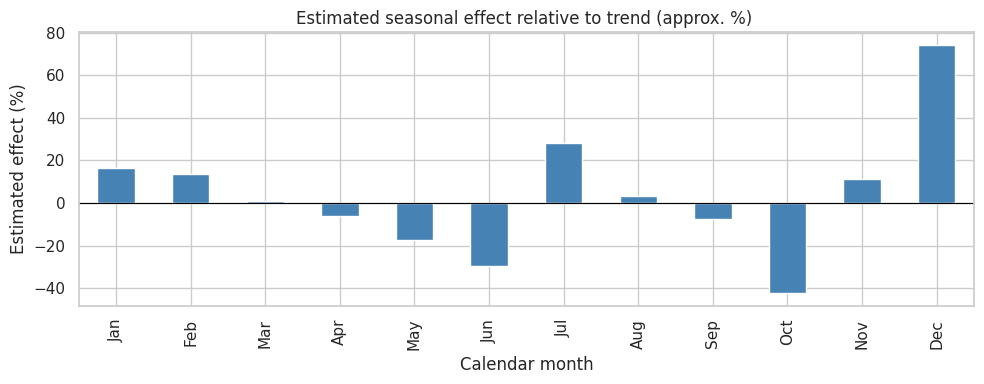

In [ ]:
# Decompose the log-transformed series into trend, seasonal, and residual components
if len(log_count) >= 24:
    decomposition = seasonal_decompose(log_count, model="additive", period=12, extrapolate_trend="freq")
    fig = decomposition.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle("Decomposition of log1p monthly review volume (period = 12 months)", y=1.02)
    plt.tight_layout()
    plt.show()

    seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
    seasonal_percent = (np.exp(seasonal_by_month) - 1) * 100
    seasonal_percent.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    ax = seasonal_percent.plot(kind="bar", figsize=(10, 4), color="steelblue")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title("Estimated seasonal effect relative to trend (approx. %) ")
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("Estimated effect (%)")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough observations for a 12-month decomposition.")

Review activity generally increased from 2010 to 2014, with a possible yearly seasonal pattern. December had the strongest positive seasonal effect, while October had the strongest negative effect. Some fluctuations remain unexplained, and the seasonal findings should be treated cautiously because the dataset covers only about four and a half years.

# 9. ACF and PACF diagnostics

ACF and PACF plots of the first differenced log1p series help identify candidate autoregressive and moving average orders. They guide the search but do not determine a model by themselves.

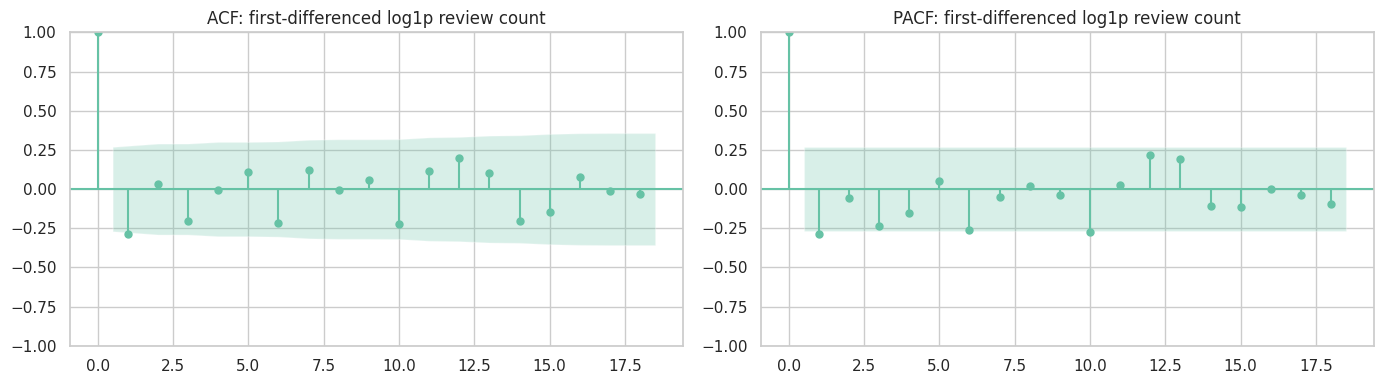

In [ ]:
# Plot ACF and PACF for the transformed series
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(log_diff.dropna(), lags=min(18, len(log_diff.dropna()) // 2 - 1), ax=axes[0])
axes[0].set_title("ACF: first-differenced log1p review count")
plot_pacf(log_diff.dropna(), lags=min(18, len(log_diff.dropna()) // 2 - 1), ax=axes[1], method="ywm")
axes[1].set_title("PACF: first-differenced log1p review count")
plt.tight_layout()
plt.show()

The ACF and PACF plots show that most autocorrelation values fall within the shaded confidence bands, suggesting weak autocorrelation in the first-differenced log review counts. A few lags fall outside or close to the bands, indicating some remaining short-term patterns. This helps guide the selection of ARIMA model parameters, but the final model should be chosen using model comparison and forecast errors.

# 10.  Fair model comparison: Naive, ARIMA, Exponential Smoothing and  SARIMA

The last 12 complete months are kept as the test set to evaluate forecasting performance. All models predict the same months, using only earlier data for training. Models trained on log-transformed review counts have their forecasts converted back to the original review-count scale using expm1.

Metrics:

- MAE: average absolute error, in reviews.

- RMSE: Shows how far forecasts are from the actual review counts, giving more weight to larger errors.

- Bias: Shows whether the model predicts too many reviews (positive) or too few reviews (negative), on average.


In [ ]:
# Split the data into training and testing sets
# Create one chronological train/test split shared by all models
if len(monthly_review_count) < 30:
    raise ValueError("There are too few monthly observations for the planned 12-month holdout.")

horizon = 12
train_count = monthly_review_count.iloc[:-horizon]
test_count = monthly_review_count.iloc[-horizon:]

train_log = np.log1p(train_count)
test_log = np.log1p(test_count)

print("Training period:", train_count.index.min().strftime("%b %Y"), "to", train_count.index.max().strftime("%b %Y"))
print("Testing period :", test_count.index.min().strftime("%b %Y"), "to", test_count.index.max().strftime("%b %Y"))
print("Forecast horizon:", horizon, "months")

Training period: Jan 2010 to Jun 2013
Testing period : Jul 2013 to Jun 2014
Forecast horizon: 12 months


The data is split chronologically, using January 2010 to June 2013 for training and July 2013 to June 2014 for testing. The training data is used to build the forecasting models, while the testing data evaluates how accurately they predict unseen observations. The forecast horizon is 12 months, meaning each model forecasts one full year of monthly review activity. Using the same split for all models ensures a fair comparison of their forecasting performance.

In [ ]:
# Define the evaluation metrics
# Calculate forecast errors using MAE, RMSE, and bias
def forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = predicted - actual

    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "Bias (forecast - actual)": float(np.mean(errors)),
    }

In [ ]:
# Define the function for converting forecasts to review counts
# Convert log1p forecasts back to non-negative review counts
def safe_count_forecast(values):
    """Convert log1p-scale predictions to non-negative counts."""
    return np.maximum(0, np.expm1(np.asarray(values, dtype=float)))

# prepare storage for forecasts and model results
# Create dictionaries and a list to store model forecasts and results
forecast_series = {}
model_fits = {}
comparison_rows = []

# Build the Naïve baseline model
# Naïve baseline: use the last training month's count for every forecast month
naive_prediction = pd.Series(
    float(train_count.iloc[-1]),
    index=test_count.index,
    name="Naïve"
)

forecast_series["1. Naïve baseline"] = naive_prediction

comparison_rows.append({
    "Model": "1. Naïve baseline",
    **forecast_metrics(test_count, naive_prediction),
    "AIC": np.nan,
    "BIC": np.nan
})

In [ ]:
# Fit and select the ARIMA model
# Search ARIMA models with different p and q values, selecting by BIC
arima_candidates = []

for p in range(3):
    for q in range(3):
        try:
            fitted = ARIMA(train_log, order=(p, 1, q), trend="n").fit()
            arima_candidates.append((fitted.bic, p, q, fitted))
        except Exception as error:
            print(f"ARIMA({p},1,{q}) did not fit: {error}")

if not arima_candidates:
    raise RuntimeError(
        "No ARIMA candidate could be fitted. Check the data and statsmodels installation."
    )

_, best_p, best_q, best_arima = min(
    arima_candidates, key=lambda item: item[0]
)

arima_prediction = pd.Series(
    safe_count_forecast(best_arima.forecast(horizon)),
    index=test_count.index,
    name="ARIMA"
)

forecast_series[f"2. ARIMA({best_p},1,{best_q})"] = arima_prediction
model_fits["ARIMA"] = best_arima

comparison_rows.append({
    "Model": f"2. ARIMA({best_p},1,{best_q})",
    **forecast_metrics(test_count, arima_prediction),
    "AIC": best_arima.aic,
    "BIC": best_arima.bic
})

print("Selected ARIMA order:", (best_p, 1, best_q))

Selected ARIMA order: (0, 1, 0)


The selected ARIMA model is (0, 1, 0) ,  means the model uses no autoregressive terms (p= 0), applies differencing once to help make the data stationary (d= 1), and uses no moving-average terms (q= 0).

In [ ]:
# Fit the Exponential Smoothing model
# Fit Exponential Smoothing with a trend, falling back to no trend if needed
try:
    ets_fit = ExponentialSmoothing(
        train_log,
        trend="add",
        seasonal=None,
        initialization_method="estimated"
    ).fit(optimized=True)

except Exception:
    ets_fit = ExponentialSmoothing(
        train_log,
        trend=None,
        seasonal=None,
        initialization_method="estimated"
    ).fit(optimized=True)

ets_prediction = pd.Series(
    safe_count_forecast(ets_fit.forecast(horizon)),
    index=test_count.index,
    name="Exponential Smoothing"
)

forecast_series["3. Exponential Smoothing"] = ets_prediction
model_fits["Exponential Smoothing"] = ets_fit

comparison_rows.append({
    "Model": "3. Exponential Smoothing",
    **forecast_metrics(test_count, ets_prediction),
    "AIC": getattr(ets_fit, "aic", np.nan),
    "BIC": getattr(ets_fit, "bic", np.nan)
})

In [ ]:
# Fit and select the SARIMA model
# Test SARIMA candidates with 12-month seasonality and select by BIC
sarima_candidates = []

for order, seasonal_order in [
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 1), (0, 1, 1, 12)),
    ((0, 1, 1), (1, 1, 0, 12)),
]:
    try:
        fitted = ARIMA(
            train_log,
            order=order,
            seasonal_order=seasonal_order,
            trend="n"
        ).fit()

        sarima_candidates.append(
            (fitted.bic, order, seasonal_order, fitted)
        )

    except Exception as error:
        print(f"SARIMA{order}x{seasonal_order} did not fit: {error}")

if sarima_candidates:
    _, best_sarima_order, best_seasonal_order, best_sarima = min(
        sarima_candidates, key=lambda item: item[0]
    )

    sarima_name = f"4. SARIMA{best_sarima_order}x{best_seasonal_order}"

    sarima_prediction = pd.Series(
        safe_count_forecast(best_sarima.forecast(horizon)),
        index=test_count.index,
        name="SARIMA"
    )

    forecast_series[sarima_name] = sarima_prediction
    model_fits["SARIMA"] = best_sarima

    comparison_rows.append({
        "Model": sarima_name,
        **forecast_metrics(test_count, sarima_prediction),
        "AIC": best_sarima.aic,
        "BIC": best_sarima.bic
    })

    print("Selected SARIMA order:", best_sarima_order)
    print("Selected seasonal order:", best_seasonal_order)

else:
    print("No SARIMA candidate fitted successfully; the other models remain available for comparison.")

Selected SARIMA order: (0, 1, 1)
Selected seasonal order: (0, 1, 1, 12)


The SARIMA model selected (0, 1, 1) * (0, 1, 1, 12) based on the lowest BIC among the tested candidates. This means the model applies first differencing and 12 month seasonal differencing to capture changes in review activity and yearly patterns. The selection identifies the best fitting candidate by BIC, but its forecasting accuracy must still be assessed using the test set error metrics.

In [ ]:
# Display the model comparison table
# Compare all fitted models using the same test period
model_comparison = pd.DataFrame(comparison_rows).set_index("Model")

display(model_comparison.round(3))

print("The table keeps the requested order: Naïve, ARIMA, Exponential Smoothing, SARIMA.")
print("MAE and RMSE measure forecast errors; bias shows over- or under-forecasting.")
print("AIC and BIC help compare candidate models within the same model family.")
print("The lowest test MAE identifies the best result for this test period, not necessarily every future period.")

,MAE,RMSE,Bias (forecast - actual),AIC,BIC
Model,,,,,
1. Naïve baseline,6.333,7.895,-2.000,NaN,NaN
"2. ARIMA(0,1,0)",6.333,7.895,-2.000,58.765,60.479
3. Exponential Smoothing,9.107,12.068,6.982,-58.566,-51.616
"4. SARIMA(0, 1, 1)x(0, 1, 1, 12)",19.537,24.585,19.464,40.313,44.415


The table keeps the requested order: Naïve, ARIMA, Exponential Smoothing, SARIMA.
MAE and RMSE measure forecast errors; bias shows over- or under-forecasting.
AIC and BIC help compare candidate models within the same model family.
The lowest test MAE identifies the best result for this test period, not necessarily every future period.


The model comparison shows that the Naive baseline and ARIMA(0,1,0) performed equally well, with an MAE of 6.333 and an RMSE of 7.895. This means their forecasts had similar errors, averaging about 6.3 reviews in absolute terms. Exponential Smoothing performed less accurately, with an MAE of 9.107, while SARIMA had the highest errors, with an MAE of 19.537. The positive bias values for Exponential Smoothing and SARIMA indicate that they generally over forecasted review counts. Since the Naive baseline and ARIMA achieved the lowest errors, either could be selected for this test period, with the Naive baseline preferred for its simplicity. AIC and BIC help compare candidate models within the same model family, rather than directly ranking all four models.

# 11. Compare forecasts visually

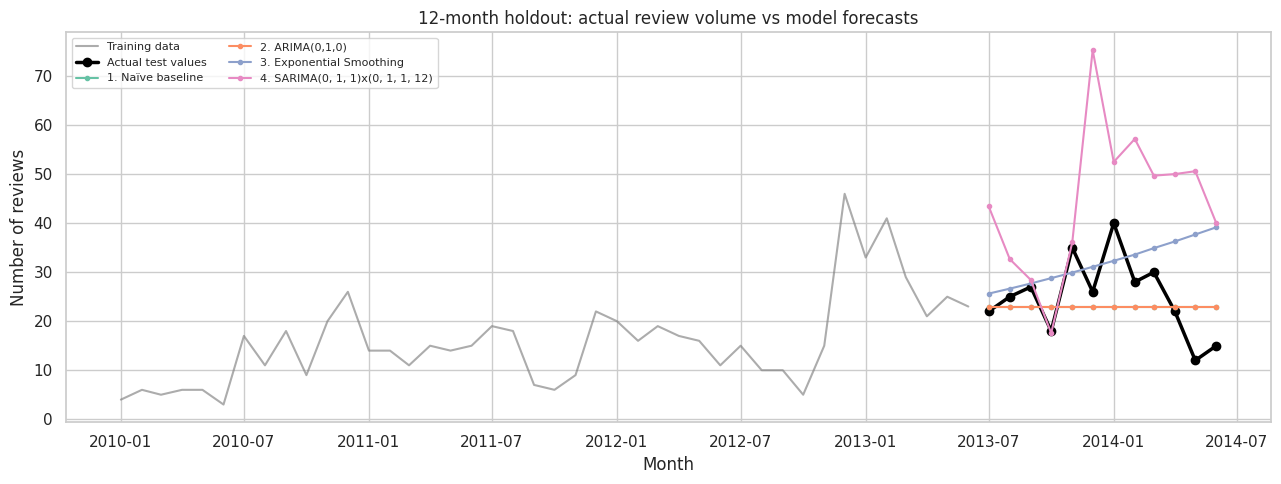

In [ ]:
# Plot actual counts and all model forecasts over the same test window
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_count.index, train_count.values, color="grey", alpha=0.65, label="Training data")
ax.plot(test_count.index, test_count.values, color="black", marker="o", lw=2.5, label="Actual test values")
for name, prediction in forecast_series.items():
    ax.plot(prediction.index, prediction.values, marker="o", ms=3, label=name)
ax.set_title("12-month holdout: actual review volume vs model forecasts")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reviews")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# 12. Forecast bias and error analysis
Bias is the average signed error (forecast minus actual). A positive value indicates over-forecasting , a negative value indicates under-forecasting.

In [ ]:
# Display error magnitude and bias for each model; the model selection below uses minimum holdout MAE
bias_error_summary = model_comparison[["MAE", "RMSE", "Bias (forecast - actual)"]].copy()
bias_error_summary["Bias direction"] = np.select(
    [bias_error_summary["Bias (forecast - actual)"] > 0.25,
     bias_error_summary["Bias (forecast - actual)"] < -0.25],
    ["Over-forecasting", "Under-forecasting"],
    default="Near-zero average bias"
)
display(bias_error_summary.round(3))

baseline_mae = model_comparison.loc["1. Naïve baseline", "MAE"]
best_model_name = model_comparison["MAE"].idxmin()
best_mae = model_comparison.loc[best_model_name, "MAE"]
if baseline_mae > 0:
    print(f"Lowest-MAE model: {best_model_name}")
    print(f"MAE improvement over naïve baseline: {(baseline_mae - best_mae) / baseline_mae * 100:.1f}%")
else:
    print("The naive baseline MAE is zero; percentage improvement is not defined.")
print("Use bias direction to decide whether workload plans may be systematically too high or too low.")

,MAE,RMSE,Bias (forecast - actual),Bias direction
Model,,,,
1. Naïve baseline,6.333,7.895,-2.000,Under-forecasting
"2. ARIMA(0,1,0)",6.333,7.895,-2.000,Under-forecasting
3. Exponential Smoothing,9.107,12.068,6.982,Over-forecasting
"4. SARIMA(0, 1, 1)x(0, 1, 1, 12)",19.537,24.585,19.464,Over-forecasting


Lowest-MAE model: 2. ARIMA(0,1,0)
MAE improvement over naïve baseline: 0.0%
Use bias direction to decide whether workload plans may be systematically too high or too low.


The Naive baseline and ARIMA model had the lowest forecast errors (MAE = 6.333), with both under-forecasting by an average of 2 reviews. ARIMA showed 0% improvement over the Naïve baseline. Exponential Smoothing and SARIMA over-forecasted review counts, with SARIMA having the largest errors. Therefore, the Naive baseline is a simple and effective choice for this test period.

# 13. Residual diagnostics for the ARIMA candidate

Residual diagnostics help determine whether the ARIMA model has left predictable patterns unexplained. These diagnostics are for the ARIMA candidate selected by BIC.

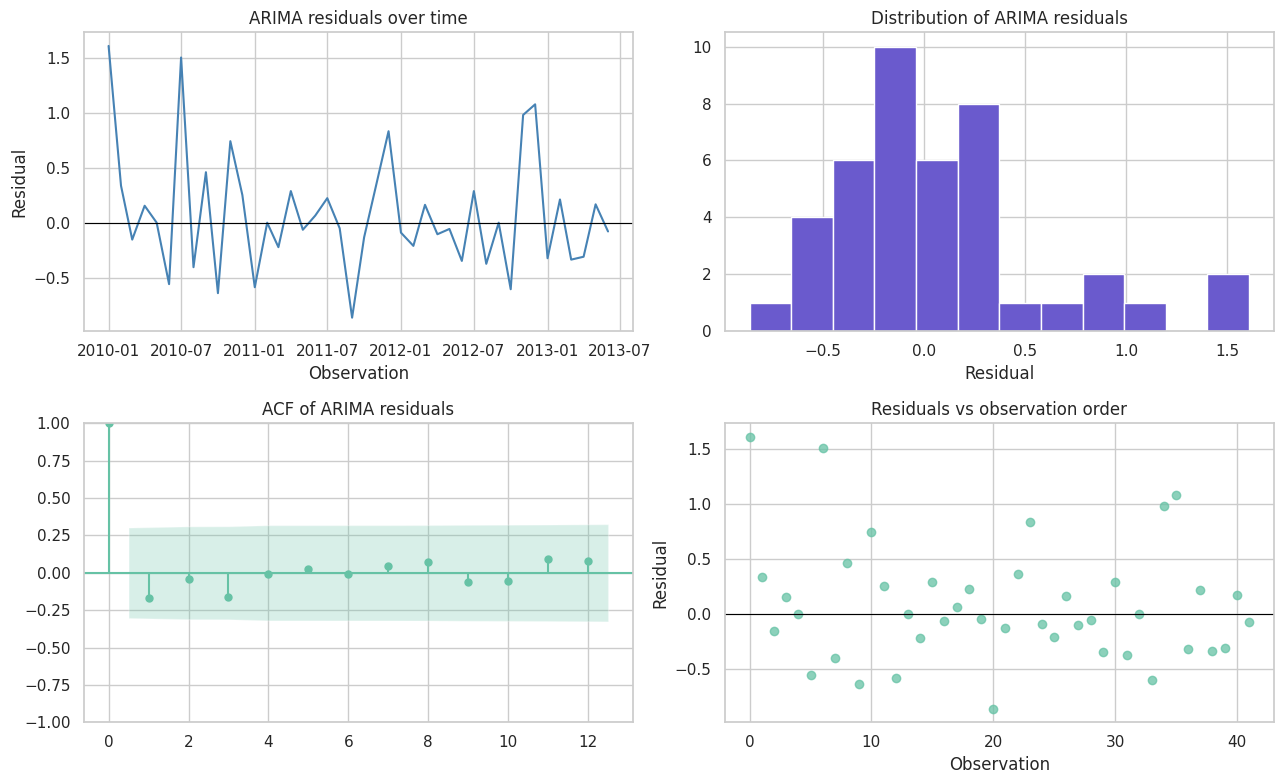

,lb_stat,lb_pvalue
6,2.572927,0.860218


Ljung–Box interpretation: no strong evidence of residual autocorrelation at the tested lag.
Also inspect the residual plots: ideally they fluctuate around zero without a clear pattern or changing spread.


In [ ]:
# Inspect ARIMA residuals and test remaining autocorrelation
arima_residuals = pd.Series(best_arima.resid).dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(arima_residuals, color="steelblue")
axes[0, 0].axhline(0, color="black", lw=0.8)
axes[0, 0].set_title("ARIMA residuals over time")
axes[0, 0].set_xlabel("Observation")
axes[0, 0].set_ylabel("Residual")
axes[0, 1].hist(arima_residuals, bins=12, edgecolor="white", color="slateblue")
axes[0, 1].set_title("Distribution of ARIMA residuals")
axes[0, 1].set_xlabel("Residual")
plot_acf(arima_residuals, lags=min(12, max(1, len(arima_residuals) // 2 - 1)), ax=axes[1, 0])
axes[1, 0].set_title("ACF of ARIMA residuals")
axes[1, 1].scatter(np.arange(len(arima_residuals)), arima_residuals, alpha=0.75)
axes[1, 1].axhline(0, color="black", lw=0.8)
axes[1, 1].set_title("Residuals vs observation order")
axes[1, 1].set_xlabel("Observation")
axes[1, 1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

lb_lag = min(6, max(1, len(arima_residuals) // 5))
try:
    ljung_box = acorr_ljungbox(arima_residuals, lags=[lb_lag], return_df=True)
    display(ljung_box)
    lb_p = float(ljung_box["lb_pvalue"].iloc[0])
    if lb_p > 0.05:
        print("Ljung–Box interpretation: no strong evidence of residual autocorrelation at the tested lag.")
    else:
        print("Ljung–Box interpretation: residual autocorrelation may remain; model refinement may be useful.")
except Exception as error:
    print("Ljung–Box test could not be calculated:", error)
print("Also inspect the residual plots: ideally they fluctuate around zero without a clear pattern or changing spread.")

The ARIMA residuals fluctuate around zero without a clear pattern, and most values fall within a reasonable range. The ACF plot shows no strong remaining autocorrelation, with the bars within the confidence limits. The Ljung Box test gives a p-value of 0.8602, which is greater than 0.05, indicating no strong evidence of residual autocorrelation at the tested lag. Overall, the diagnostics suggest that the model captures the main patterns in the data reasonably well, although some unusual residual values remain.

# 14. Forecast uncertainty and the final 12 month operational forecast

I refit the best performing model from the holdout comparison on all available monthly observations and forecast the next 12 months.

In [ ]:
# Refit the selected model family on all available observations and forecast 12 future months
best_family = best_model_name.split(". ", 1)[-1]
full_log = np.log1p(monthly_review_count)
future_index = pd.date_range(monthly_review_count.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")

if best_family == "Naïve baseline":
    future_mean = np.repeat(float(monthly_review_count.iloc[-1]), 12)
    # Approximate interval from historical one-step naïve errors
    naive_errors = monthly_review_count.diff().dropna()
    interval_scale = float(naive_errors.std()) if len(naive_errors) > 1 else 0.0
    future_lower = np.maximum(0, future_mean - 1.282 * interval_scale)
    future_upper = np.maximum(future_lower, future_mean + 1.282 * interval_scale)
    interval_note = "Approximate 80% range using historical one-step naïve error spread; not a calibrated model interval."
elif best_family.startswith("ARIMA"):
    full_fit = ARIMA(full_log, order=(best_p, 1, best_q), trend="n").fit()
    full_fc = full_fit.get_forecast(steps=12)
    future_mean = safe_count_forecast(full_fc.predicted_mean)
    log_ci = full_fc.conf_int(alpha=0.20)
    future_lower = np.maximum(0, np.expm1(log_ci.iloc[:, 0].to_numpy()))
    future_upper = np.maximum(future_lower, np.expm1(log_ci.iloc[:, 1].to_numpy()))
    interval_note = "Approximate 80% model-based prediction interval back-transformed from log1p scale."
elif best_family.startswith("Exponential Smoothing"):
    full_ets = ExponentialSmoothing(full_log, trend="add", seasonal=None, initialization_method="estimated").fit(optimized=True)
    future_mean = safe_count_forecast(full_ets.forecast(12))
    resid_scale = float(np.std(np.asarray(full_ets.resid), ddof=1)) if len(full_ets.resid) > 1 else 0.0
    future_lower = np.maximum(0, np.expm1(np.log1p(future_mean) - 1.282 * resid_scale))
    future_upper = np.maximum(future_lower, np.expm1(np.log1p(future_mean) + 1.282 * resid_scale))
    interval_note = "Approximate 80% range based on in-sample residual spread; Exponential Smoothing does not provide this interval directly here."
elif best_family.startswith("SARIMA") and sarima_candidates:
    full_fit = ARIMA(full_log, order=best_sarima_order, seasonal_order=best_seasonal_order, trend="n").fit()
    full_fc = full_fit.get_forecast(steps=12)
    future_mean = safe_count_forecast(full_fc.predicted_mean)
    log_ci = full_fc.conf_int(alpha=0.20)
    future_lower = np.maximum(0, np.expm1(log_ci.iloc[:, 0].to_numpy()))
    future_upper = np.maximum(future_lower, np.expm1(log_ci.iloc[:, 1].to_numpy()))
    interval_note = "Approximate 80% model-based prediction interval back-transformed from log1p scale."
else:
    # Defensive fallback if a model family could not be refitted
    future_mean = np.repeat(float(monthly_review_count.iloc[-1]), 12)
    interval_scale = float(monthly_review_count.diff().dropna().std())
    future_lower = np.maximum(0, future_mean - 1.282 * interval_scale)
    future_upper = future_mean + 1.282 * interval_scale
    interval_note = "Fallback approximate range based on historical month-to-month changes."

future_forecast = pd.DataFrame({
    "forecast_review_count": future_mean,
    "lower_80_approx": future_lower,
    "upper_80_approx": future_upper,
}, index=future_index)
future_forecast.index.name = "month"
display(future_forecast.round(1))
print("Selected model family:", best_model_name)
print(interval_note)

,forecast_review_count,lower_80_approx,upper_80_approx
month,,,
2014-07-01,15.0,7.9,27.7
2014-08-01,15.0,6.0,35.5
2014-09-01,15.0,4.8,43.0
2014-10-01,15.0,4.0,50.4
2014-11-01,15.0,3.3,58.1
2014-12-01,15.0,2.8,65.9
2015-01-01,15.0,2.4,74.0
2015-02-01,15.0,2.1,82.5
2015-03-01,15.0,1.8,91.3


Selected model family: 2. ARIMA(0,1,0)
Approximate 80% model-based prediction interval back-transformed from log1p scale.


The selected ARIMA(0,1,0) model forecasts approximately 15 reviews per month from July 2014 to June 2015. The approximate 80% prediction intervals become wider over time, showing increasing uncertainty in forecasts further into the future. These forecasts can help with operational planning, but they should be treated cautiously because uncertainty increases with the forecast horizon.

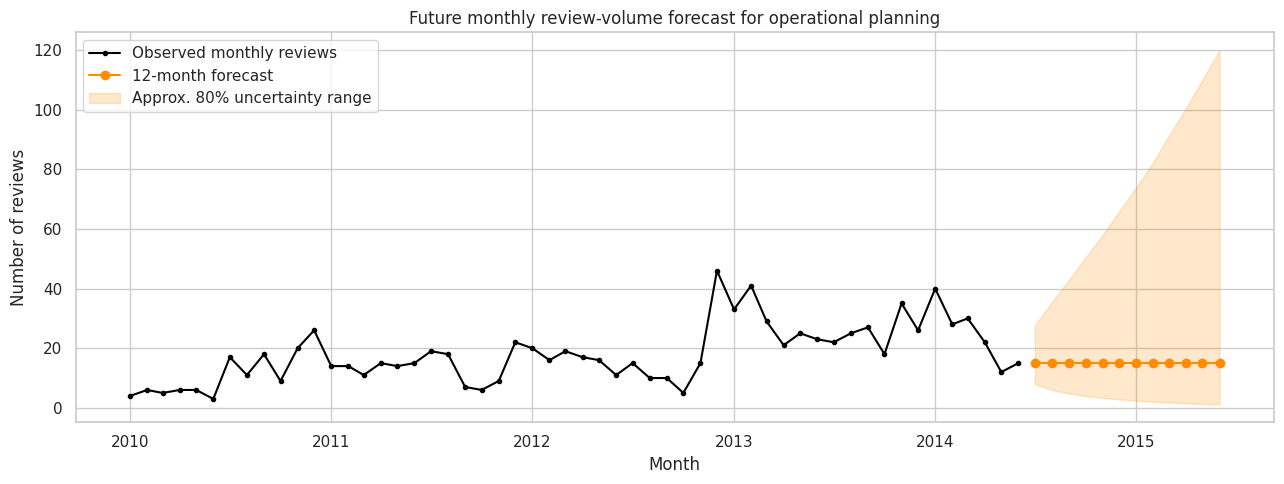

In [ ]:
# Plot the historical data and future forecast with its uncertainty range
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly_review_count.index, monthly_review_count.values, color="black", marker="o", ms=3, label="Observed monthly reviews")
ax.plot(future_forecast.index, future_forecast["forecast_review_count"], color="darkorange", marker="o", label="12-month forecast")
ax.fill_between(
    future_forecast.index,
    future_forecast["lower_80_approx"].to_numpy(),
    future_forecast["upper_80_approx"].to_numpy(),
    color="darkorange", alpha=0.2, label="Approx. 80% uncertainty range"
)
ax.set_title("Future monthly review-volume forecast for operational planning")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reviews")
ax.legend()
plt.tight_layout()
plt.show()

# 15. Walk-forward validation

Walk-forward validation repeatedly trains on past observations and predicts a short future window.

,MAE,RMSE,Bias (forecast - actual)
Model,,,
ARIMA,7.722,8.551,3.944
Naïve baseline,7.722,8.551,3.944
Exponential Smoothing,9.544,10.298,3.018
SARIMA,10.628,13.798,4.600


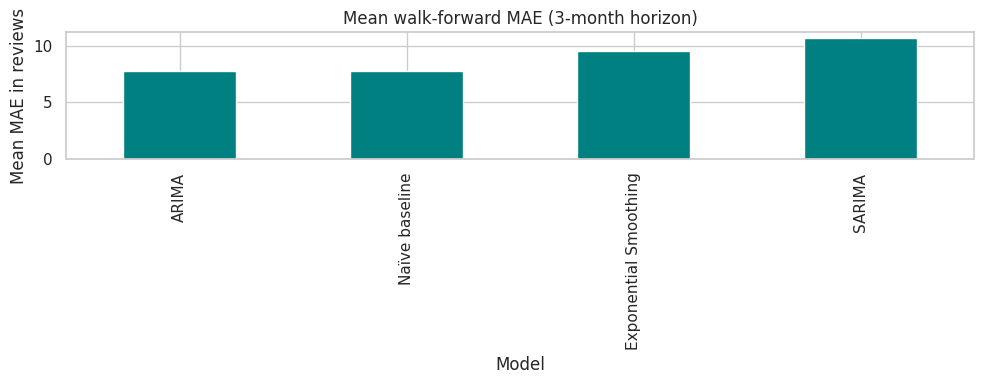

In [ ]:
# Evaluate Naïve, ARIMA, Exponential Smoothing, and SARIMA over expanding training windows
walk_rows = []
initial_train = max(24, len(monthly_review_count) - 18)
validation_horizon = 3

for start in range(initial_train, len(monthly_review_count) - validation_horizon + 1, validation_horizon):
    history = monthly_review_count.iloc[:start]
    actual = monthly_review_count.iloc[start:start + validation_horizon]
    history_log = np.log1p(history)
    origin = history.index[-1]
    fold_predictions = {}

    # Naïve baseline
    fold_predictions["Naïve baseline"] = np.repeat(float(history.iloc[-1]), len(actual))

    # ARIMA using the order selected in the training-only candidate search above
    try:
        fold_arima = ARIMA(history_log, order=(best_p, 1, best_q), trend="n").fit()
        fold_predictions["ARIMA"] = safe_count_forecast(fold_arima.forecast(len(actual)))
    except Exception:
        pass

    # Exponential Smoothing
    try:
        fold_ets = ExponentialSmoothing(history_log, trend="add", seasonal=None, initialization_method="estimated").fit(optimized=True)
        fold_predictions["Exponential Smoothing"] = safe_count_forecast(fold_ets.forecast(len(actual)))
    except Exception:
        pass

    # SARIMA, if the seasonal candidate fitted successfully
    if sarima_candidates:
        try:
            fold_sarima = ARIMA(history_log, order=best_sarima_order, seasonal_order=best_seasonal_order, trend="n").fit()
            fold_predictions["SARIMA"] = safe_count_forecast(fold_sarima.forecast(len(actual)))
        except Exception:
            pass

    for model_name, prediction in fold_predictions.items():
        fold_metrics = forecast_metrics(actual, prediction)
        walk_rows.append({"Origin": origin, "Model": model_name, **fold_metrics})

walk_forward_results = pd.DataFrame(walk_rows)
if not walk_forward_results.empty:
    walk_summary = walk_forward_results.groupby("Model")[["MAE", "RMSE", "Bias (forecast - actual)"]].mean().sort_values("MAE")
    display(walk_summary.round(3))
    ax = walk_summary["MAE"].sort_values().plot(kind="bar", figsize=(10, 4), color="teal")
    ax.set_title("Mean walk-forward MAE (3-month horizon)")
    ax.set_xlabel("Model")
    ax.set_ylabel("Mean MAE in reviews")
    plt.tight_layout()
    plt.show()
else:
    print("Walk-forward validation did not produce any folds; check the number of monthly observations.")

The walk-forward validation shows that ARIMA and the Naive baseline performed equally well, with a mean MAE of 7.722 reviews. Exponential Smoothing had higher errors, while SARIMA performed worst, with a mean MAE of 10.628. All models had positive bias, meaning they generally over-forecasted review counts. These results support choosing the simpler Naive baseline, as ARIMA did not improve forecasting accuracy across the validation periods.

# 16. Optional Sentiment Analysis

The dataset contains sentiment labels that identify reviews as positive, negative, or neutral. I examine the monthly proportions of each sentiment to understand how customer opinions change over time. This analysis provides additional context about customer satisfaction but is not used in the main review volume forecasting models. The accuracy of the supplied sentiment labels is not evaluated.

sentiment_label,negative,neutral,positive
month,,,
2013-09-01,0.185,0.037,0.778
2013-10-01,0.111,0.056,0.833
2013-11-01,0.114,0.029,0.857
2013-12-01,0.115,0.077,0.808
2014-01-01,0.075,0.050,0.875
2014-02-01,0.214,0.036,0.750
2014-03-01,0.100,0.033,0.867
2014-04-01,0.182,0.091,0.727
2014-05-01,0.083,0.167,0.750


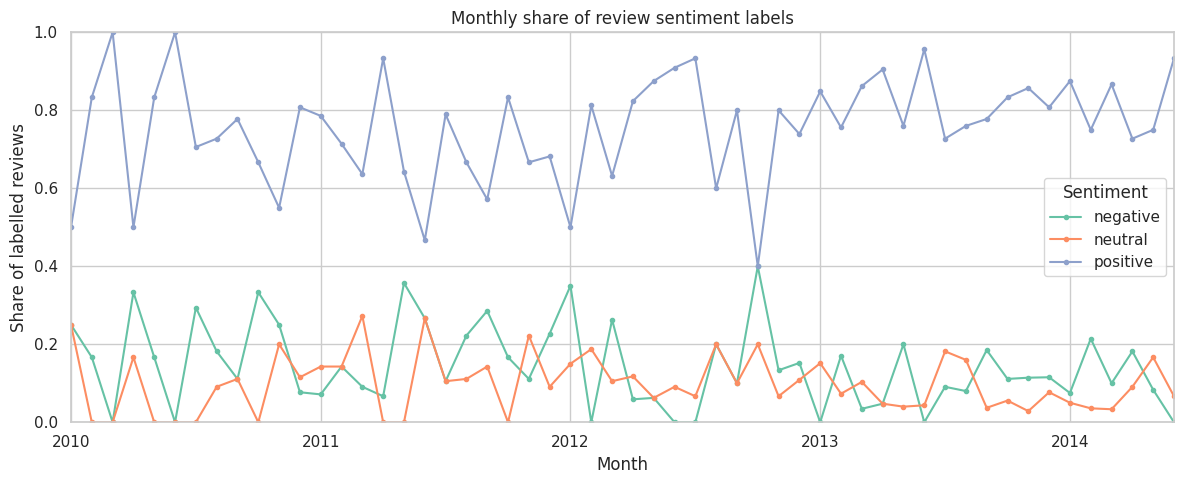

In [ ]:
# Summarize monthly sentiment shares when a sentiment label is available
if "sentiment_label" in df.columns:
    sentiment_source = df.dropna(subset=["timestamp", "sentiment_label"]).copy()
    sentiment_source["sentiment_label"] = sentiment_source["sentiment_label"].astype(str).str.lower().str.strip()
    sentiment_counts = sentiment_source.set_index("timestamp").groupby(
        [pd.Grouper(freq="MS"), "sentiment_label"]
    ).size().unstack(fill_value=0)
    sentiment_counts = sentiment_counts.reindex(monthly.index, fill_value=0)
    sentiment_share = sentiment_counts.div(sentiment_counts.sum(axis=1).replace(0, np.nan), axis=0)
    display(sentiment_share.tail(10).round(3))
    ax = sentiment_share.plot(figsize=(12, 5), marker="o", ms=3)
    ax.set_title("Monthly share of review sentiment labels")
    ax.set_xlabel("Month")
    ax.set_ylabel("Share of labelled reviews")
    ax.set_ylim(0, 1)
    ax.legend(title="Sentiment")
    plt.tight_layout()
    plt.show()
else:
    print("No sentiment_label column found; skipping optional sentiment analysis.")

The chart shows that positive reviews dominate throughout the period, generally accounting for around 70% - 90% of labelled reviews. Negative reviews make up a smaller share but increase in some months, while neutral reviews usually have the lowest share. In June 2014, positive reviews reached about 93.3%, while negative reviews were 0%. Customer sentiment was mostly positive, although the proportions fluctuated from month to month.

In [ ]:
# Build a final comparison table from the calculated holdout results
final_model_comparison = model_comparison[
    ["MAE", "RMSE", "Bias (forecast - actual)", "AIC", "BIC"]
].copy()

# Mark every model tied for the lowest holdout MAE
lowest_mae = final_model_comparison["MAE"].min()
final_model_comparison["Holdout result"] = np.where(
    np.isclose(final_model_comparison["MAE"], lowest_mae),
    "Best / tied on MAE",
    "Higher MAE"
)

# Keep the requested model order: Naive, ARIMA, Exponential Smoothing, SARIMA
display(final_model_comparison.round(3))

,MAE,RMSE,Bias (forecast - actual),AIC,BIC,Holdout result
Model,,,,,,
1. Naïve baseline,6.333,7.895,-2.000,NaN,NaN,Best / tied on MAE
"2. ARIMA(0,1,0)",6.333,7.895,-2.000,58.765,60.479,Best / tied on MAE
3. Exponential Smoothing,9.107,12.068,6.982,-58.566,-51.616,Higher MAE
"4. SARIMA(0, 1, 1)x(0, 1, 1, 12)",19.537,24.585,19.464,40.313,44.415,Higher MAE


## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


# Goal

# Business goal:

build and evaluate neural-network models using the supplied Amazon reviews dataset to (1) classify a review into a 1 - 5 star rating and (2) estimate its rating as a numeric value. Compare model performance with simple baselines, explain the results, and identify practical next steps.

## Questions this to answers

1. What does the Amazon dataset contain, and is it suitable for modelling?
2. Can review text predict the 1 - 5 star rating better than a simple majority class baseline?
3. How well does the model recognise each rating, especially underrepresented ratings?
4. Can a neural network estimate the numeric rating, and what are its MAE, RMSE and (R^2)?
5. What changes when the same classification task is implemented in Keras and, if PyTorch is installed, PyTorch?
6. What are the limitations, business implications and possible improvements?

## Workflow

Load and inspect , clean text , split into train/validation/test , fit TF-IDF on training data only , train baseline and neural networks , tune using validation results , evaluate once on the held-out test set , interpret results and limitations.

#Evaluation rule:

the test set is kept separate from model selection. Validation results guide tuning; final test results estimate performance on unseen reviews.



In [29]:
#preview dataset
# Display the existing dataset information
print("Dataset shape:", df.shape)
display(df.head())

print("\nColumns:", df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

Dataset shape: (997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60



Columns: ['product_id', 'rating', 'review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label', 'review_length_words']

Data types:


,dtype
product_id,object
rating,int64
review_text,object
review_summary,object
review_time_raw,object
unix_review_time,float64
timestamp,object
sentiment_label,object
review_length_words,int64


In [30]:
# Check data quality before cleaning
print("Missing values per column:")
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())

required_columns = {"review_text", "rating"}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {missing_required}")

print("\nRating values:")
display(df["rating"].value_counts(dropna=False).sort_index())

Missing values per column:


,missing_values
product_id,0
rating,0
review_text,0
review_summary,0
review_time_raw,0
unix_review_time,0
timestamp,0
sentiment_label,0
review_length_words,0


Duplicate rows: 0

Rating values:


,count
rating,
1,87
2,48
3,94
4,188
5,580


The dataset contains 997 reviews, with no missing values or duplicate rows. Most reviews are positive, with 580 customers giving 5 stars and 188  giving 4 stars. Only 135 reviews received 1 or 2 stars, while 94 received 3 stars.

# 3. Clean the text and explore the target

I remove rows that do not have a rating or review text, remove exact duplicate rows, normalise HTML entities and whitespace, and drop empty reviews. We do not alter the rating values. The class distribution is plotted because imbalanced classes can make accuracy look better than the model's ability to recognise every rating.

In [31]:
# Keep only usable rows and clean the review text
model_df = df[["review_text", "rating"]].copy()
model_df = model_df.dropna(subset=["review_text", "rating"])
model_df = model_df.drop_duplicates()
model_df["review_text"] = model_df["review_text"].astype(str)

def clean_review(text):
    text = html.unescape(text)                  # Convert entities such as &quot;
    text = re.sub(r"<[^>]+>", " ", text)        # Remove HTML tags
    text = re.sub(r"\s+", " ", text).strip()    # Standardise whitespace
    return text.lower()

model_df["clean_text"] = model_df["review_text"].apply(clean_review)
model_df = model_df[model_df["clean_text"].str.len() > 0].copy()
model_df["rating"] = pd.to_numeric(model_df["rating"], errors="coerce")
model_df = model_df.dropna(subset=["rating"])
model_df = model_df[model_df["rating"].isin([1, 2, 3, 4, 5])].copy()
model_df["rating"] = model_df["rating"].astype(int)

print("Rows available for modelling:", len(model_df))
print("Rating counts:")
display(model_df["rating"].value_counts().sort_index().to_frame("count"))

Rows available for modelling: 997
Rating counts:


,count
rating,
1,87
2,48
3,94
4,188
5,580


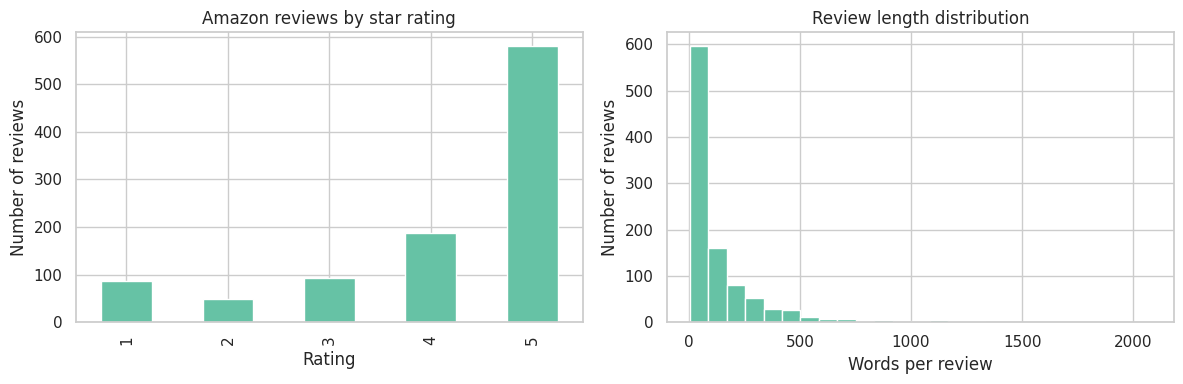

Average words per review: 146.4
Median words per review: 67


In [32]:
# Visualise rating imbalance and review length
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

model_df["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Amazon reviews by star rating")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of reviews")

model_df["word_count"] = model_df["clean_text"].str.split().str.len()
axes[1].hist(model_df["word_count"], bins=25)
axes[1].set_title("Review length distribution")
axes[1].set_xlabel("Words per review")
axes[1].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

print("Average words per review:", round(model_df["word_count"].mean(), 1))
print("Median words per review:", int(model_df["word_count"].median()))

The average review contains 146 words, while the median is 67 words. This means some long reviews increase the average, making it much higher than the median.

# 4. Split the data before vectorising

I use a stratified 60% training , 20% validation , 20% test split so that each split has a similar rating distribution. The TF-IDF vectoriser is fitted on training text only.Validation and test text are transformed with that fitted vectoriser. This prevents vocabulary IDF information from the held out data leaking into training.

TF-IDF turns text into a numeric vector and max_features limits the vocabulary to keep this small dataset and the neural network manageable.

In [33]:
# Create train, validation and test splits (stratified by rating)
X_text = model_df["clean_text"].to_numpy()
y_rating = model_df["rating"].to_numpy()

X_train_text, X_temp_text, y_train_rating, y_temp_rating = train_test_split(
    X_text, y_rating, test_size=0.40, random_state=SEED, stratify=y_rating
)
X_val_text, X_test_text, y_val_rating, y_test_rating = train_test_split(
    X_temp_text, y_temp_rating, test_size=0.50, random_state=SEED, stratify=y_temp_rating
)

print(f"Train: {len(X_train_text)} ({len(X_train_text)/len(model_df):.0%})")
print(f"Validation: {len(X_val_text)} ({len(X_val_text)/len(model_df):.0%})")
print(f"Test: {len(X_test_text)} ({len(X_test_text)/len(model_df):.0%})")

Train: 598 (60%)
Validation: 199 (20%)
Test: 200 (20%)


The dataset of 997 reviews is divided into three sets; 598 reviews (60%) for training, 199 (20%) for validation, and 200 (20%) for testing. The training set is used to teach the model, the validation set helps tune and improve its performance, and the test set evaluates how well it performs on unseen reviews. This split supports a fair assessment of the sentiment analysis model.

In [34]:
# Fit TF-IDF on training text only, then transform validation and test text
vectorizer = TfidfVectorizer(
    max_features=1500,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text).toarray().astype("float32")
X_val = vectorizer.transform(X_val_text).toarray().astype("float32")
X_test = vectorizer.transform(X_test_text).toarray().astype("float32")

# Classification labels are encoded as 0–4 for the five output neurons
y_train_cls = (y_train_rating - 1).astype("int64")
y_val_cls = (y_val_rating - 1).astype("int64")
y_test_cls = (y_test_rating - 1).astype("int64")

# Regression uses the original numeric 1–5 rating
y_train_reg = y_train_rating.astype("float32")
y_val_reg = y_val_rating.astype("float32")
y_test_reg = y_test_rating.astype("float32")

print("TF-IDF matrix shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

TF-IDF matrix shapes: (598, 1500) (199, 1500) (200, 1500)
Vocabulary size: 1500


TF-IDF converted the review text into numerical features, using a vocabulary of 1,500 words and phrases. The training set contains 598 reviews, the validation set 199, and the test set 200. Each review is represented by 1,500 numerical features.
TF-IDF is fitted only on the training data to prevent data leakage. The same vocabulary is then applied to the validation and test sets. The resulting features can be used to train machine learning and neural network models for rating classification and regression.

# 5. Define evaluation helpers and a simple baseline

The majority class baseline always predicts the most common rating. It is not a neural network, it provides a minimum reference point that a useful classifier should improve upon. For regression, the baseline predicts the average training rating for every review.

In [35]:
# Establish simple baselines without using test data for fitting
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train_cls)
baseline_val_pred = majority_model.predict(X_val)

print("Majority baseline validation accuracy:", round(accuracy_score(y_val_cls, baseline_val_pred), 4))
print("Majority baseline validation macro-F1:", round(f1_score(y_val_cls, baseline_val_pred, average="macro", zero_division=0), 4))

reg_baseline = DummyRegressor(strategy="mean")
reg_baseline.fit(X_train, y_train_reg)
baseline_reg_val = reg_baseline.predict(X_val)
print("Mean-rating regression baseline validation MAE:", round(mean_absolute_error(y_val_reg, baseline_reg_val), 4))
print("Mean-rating regression baseline RMSE:", round(np.sqrt(mean_squared_error(y_val_reg, baseline_reg_val)), 4))

Majority baseline validation accuracy: 0.5829
Majority baseline validation macro-F1: 0.1473
Mean-rating regression baseline validation MAE: 1.0135
Mean-rating regression baseline RMSE: 1.2772


The majority class classification model achieved 58.29% validation accuracy, but its macro F1 score is only 0.1473, This is because it always predicts the most common rating class and performs poorly on the other rating classes.

The mean rating regression model achieved an MAE of 1.0135 and an RMSE of 1.2772, meaning its predictions differ from actual ratings by about one star on average.

These results provide baseline performance levels. More advanced models should aim to improve classification performance across all rating classes and reduce regression errors.

# 6. Keras neural network — rating classification

# Architecture choices

- Model type

 Multi-layer perceptron (MLP) for classifying reviews into five rating classes.

- Input

 TF-IDF features extracted from review text.

- Hidden layers

 Dense layers with 64 and 32 neurons, using ReLU activation to learn patterns in the text.

- Dropout

 Reduces overfitting by randomly deactivating neurons during training.

- Output layer

 Five neurons with softmax activation to predict probabilities for ratings 1 - 5.

- Loss function

 Sparse categorical cross-entropy, suitable for integer-encoded class labels (0 - 4).

- Early stopping

 Monitors validation loss and restores the best model weights to help prevent overfitting.

- Data separation

 Validation data is used for model tuning, while test data is reserved for final evaluation.

I use early stopping based on validation loss and restore the best weights. Validation data is not used as the final test.

In [36]:
# Build a compact Keras classifier to limit overfitting on this small dataset
def build_keras_classifier(input_dim, dropout_rate=0.30, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(5, activation="softmax")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

keras_classifier = build_keras_classifier(X_train.shape[1])
keras_classifier.summary()

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

keras_history = keras_classifier.fit(
    X_train, y_train_cls,
    validation_data=(X_val, y_val_cls),
    epochs=40,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
print("Epochs completed:", len(keras_history.history["loss"]))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │        96,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,309 (384.02 KB)

 Trainable params: 98,309 (384.02 KB)

 Non-trainable params: 0 (0.00 B)

Epochs completed: 12


The Keras neural network uses two hidden layers with 64 and 32 neurons, dropout layers to reduce overfitting, and an output layer with five neurons to predict ratings from 1 to 5. The model has 98,309 trainable parameters and completed 12 epochs instead of the maximum 40 because early stopping halted training. This helps reduce overfitting, but the model's performance must be confirmed using validation metrics and final test results.

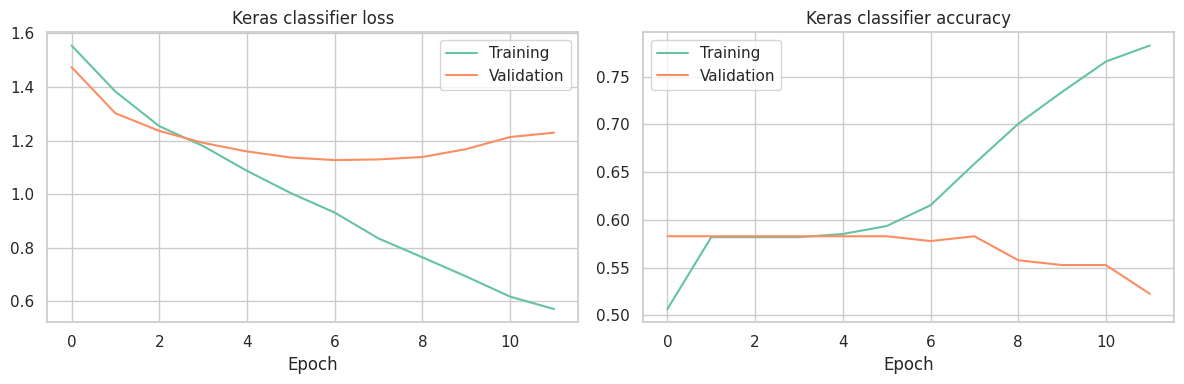

In [37]:
# Plot training and validation loss/accuracy to check for overfitting
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(keras_history.history["loss"], label="Training")
axes[0].plot(keras_history.history["val_loss"], label="Validation")
axes[0].set_title("Keras classifier loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(keras_history.history["accuracy"], label="Training")
axes[1].plot(keras_history.history["val_accuracy"], label="Validation")
axes[1].set_title("Keras classifier accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# 7. Classification Evaluation on the Held-Out Test Set

- Accuracy

 Measures the percentage of ratings correctly predicted by the model.

- Macro-F1 score

 Calculates the average F1 score across all rating classes equally, highlighting poor performance on less common ratings.

- Confusion matrix

 Shows how often the model correctly predicts each rating and which ratings it confuses with others.

- Test set

 Evaluates the model on unseen data to assess how well it generalizes to new reviews.

Keras test accuracy: 0.6000
Keras test macro-F1: 0.1852

Classification report:
              precision    recall  f1-score   support

      1 star       0.00      0.00      0.00        18
     2 stars       0.00      0.00      0.00         9
     3 stars       0.00      0.00      0.00        19
     4 stars       0.44      0.11      0.17        38
     5 stars       0.61      1.00      0.76       116

    accuracy                           0.60       200
   macro avg       0.21      0.22      0.19       200
weighted avg       0.44      0.60      0.47       200



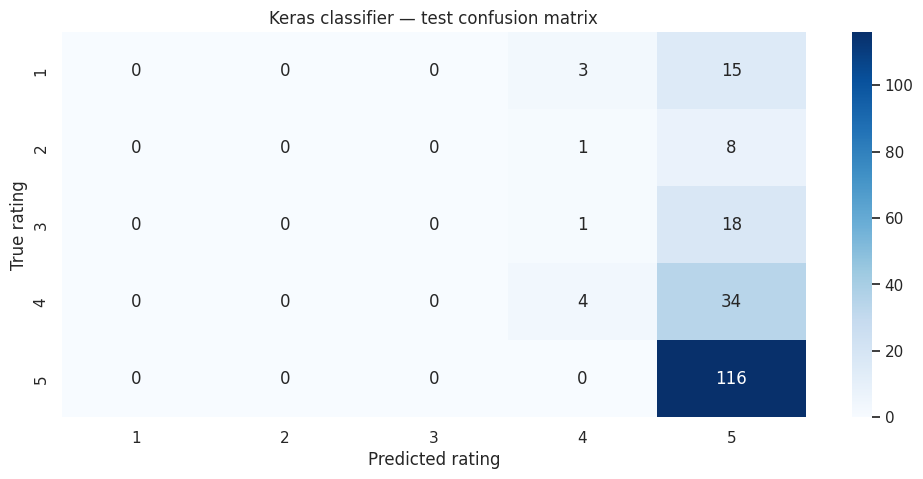

In [38]:
# Evaluate the Keras classifier once on the held-out test data
keras_test_prob = keras_classifier.predict(X_test, verbose=0)
keras_test_pred = keras_test_prob.argmax(axis=1)

keras_test_accuracy = accuracy_score(y_test_cls, keras_test_pred)
keras_test_macro_f1 = f1_score(y_test_cls, keras_test_pred, average="macro", zero_division=0)

print(f"Keras test accuracy: {keras_test_accuracy:.4f}")
print(f"Keras test macro-F1: {keras_test_macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test_cls, keras_test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
    zero_division=0
))

cm = confusion_matrix(y_test_cls, keras_test_pred, labels=[0, 1, 2, 3, 4])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
plt.title("Keras classifier — test confusion matrix")
plt.xlabel("Predicted rating")
plt.ylabel("True rating")
plt.show()

The Keras classifier achieved 60% test accuracy and a macro-F1 score of 0.1852. It correctly identified all 116 five star reviews but failed to correctly classify any 1, 2, or 3 star reviews and performed poorly on four star reviews. This shows that the model favours five star predictions and struggles with less common ratings due to class imbalance. Further improvements are needed to achieve better performance across all five rating classes.

# 8. Improve classification: compare a small set of hyperparameters

I compare a baseline architecture with a smaller dropout rate and a class weighted version. Class weights give more importance to errors on less frequent ratings, Each experiment is selected using validation macro-F1. The test set is not used to select the best configuration.

Because the dataset is small and imbalanced, class weighting may improve minority-class recall while reducing overall accuracy. This is a trade-off, not a guaranteed improvement.

In [39]:
# Calculate class weights from the training labels only
class_ids = np.arange(5)
weights = compute_class_weight(class_weight="balanced", classes=class_ids, y=y_train_cls)
class_weights = {int(class_id): float(weight) for class_id, weight in zip(class_ids, weights)}
print("Training class weights:", {i + 1: round(w, 2) for i, w in class_weights.items()})

experiments = [
    {"name": "Baseline MLP (dropout 0.30)", "dropout": 0.30, "lr": 0.001, "weighted": False},
    {"name": "Lower dropout (0.10)", "dropout": 0.10, "lr": 0.001, "weighted": False},
    {"name": "Class-weighted MLP", "dropout": 0.30, "lr": 0.001, "weighted": True},
]
experiment_rows = []
experiment_models = {}

for exp in experiments:
    tf.keras.backend.clear_session()
    model = build_keras_classifier(
        X_train.shape[1],
        dropout_rate=exp["dropout"],
        learning_rate=exp["lr"]
    )
    fit_args = {}
    if exp["weighted"]:
        fit_args["class_weight"] = class_weights

    hist = model.fit(
        X_train, y_train_cls,
        validation_data=(X_val, y_val_cls),
        epochs=35,
        batch_size=32,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True
        )],
        verbose=0,
        **fit_args
    )
    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    row = {
        "Experiment": exp["name"],
        "Validation accuracy": accuracy_score(y_val_cls, val_pred),
        "Validation macro-F1": f1_score(y_val_cls, val_pred, average="macro", zero_division=0),
        "Epochs trained": len(hist.history["loss"])
    }
    experiment_rows.append(row)
    experiment_models[exp["name"]] = model

experiment_results = pd.DataFrame(experiment_rows).sort_values(
    "Validation macro-F1", ascending=False
).reset_index(drop=True)
display(experiment_results.style.format({
    "Validation accuracy": "{:.3f}",
    "Validation macro-F1": "{:.3f}"
}))
best_experiment_name = experiment_results.loc[0, "Experiment"]
best_classifier = experiment_models[best_experiment_name]
print("Selected using validation macro-F1:", best_experiment_name)

Training class weights: {1: 2.3, 2: 4.12, 3: 2.14, 4: 1.06, 5: 0.34}


,Experiment,Validation accuracy,Validation macro-F1,Epochs trained
0,Class-weighted MLP,0.492,0.294,16
1,Lower dropout (0.10),0.578,0.165,12
2,Baseline MLP (dropout 0.30),0.573,0.156,12


Selected using validation macro-F1: Class-weighted MLP


The class weights give more importance to underrepresented ratings, especially 2 star reviews (4.12), while reducing the importance of common 5 star reviews (0.34). The class weighted MLP performed best, achieving a validation macro-F1 score of 0.294 and accuracy of 49.2%, although its accuracy is lower than the other models, its higher macro-F1 indicates better performance across the five rating classes.

The class-weighted MLP is selected for further evaluation because it achieved the highest validation macro-F1 score.

Selected model test accuracy: 0.5450
Selected model test macro-F1: 0.3381
              precision    recall  f1-score   support

      1 star       0.22      0.39      0.28        18
     2 stars       0.17      0.11      0.13         9
     3 stars       0.27      0.21      0.24        19
     4 stars       0.34      0.26      0.30        38
     5 stars       0.74      0.75      0.74       116

    accuracy                           0.55       200
   macro avg       0.35      0.34      0.34       200
weighted avg       0.55      0.55      0.54       200



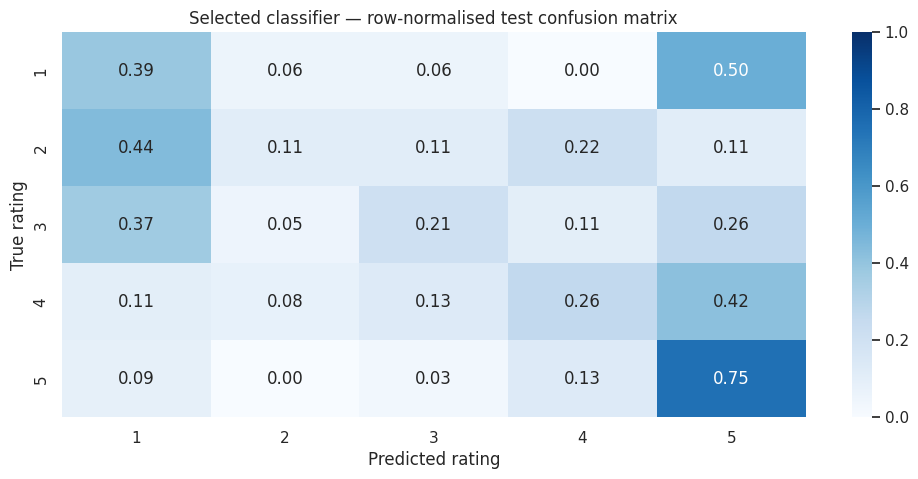

In [40]:
# Final evaluation of the selected classifier on the test set
best_test_pred = best_classifier.predict(X_test, verbose=0).argmax(axis=1)
best_test_accuracy = accuracy_score(y_test_cls, best_test_pred)
best_test_macro_f1 = f1_score(y_test_cls, best_test_pred, average="macro", zero_division=0)

print(f"Selected model test accuracy: {best_test_accuracy:.4f}")
print(f"Selected model test macro-F1: {best_test_macro_f1:.4f}")
print(classification_report(
    y_test_cls, best_test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
    zero_division=0
))

cm = confusion_matrix(y_test_cls, best_test_pred, labels=[0, 1, 2, 3, 4], normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5],
            vmin=0, vmax=1)
plt.title("Selected classifier — row-normalised test confusion matrix")
plt.xlabel("Predicted rating")
plt.ylabel("True rating")
plt.show()

The selected class-weighted MLP achieved 54.5% test accuracy and a macro-F1 score of 0.3381. It performed best on 5 star reviews, with an F1 score of 0.74, while classification of 1 to 4 star reviews remained weaker. Compared with the original model's macro-F1 of 0.1852, the selected model improved performance across rating classes, although overall accuracy decreased. This suggests that class weighting helped the model recognize less common ratings, but further improvements are needed for reliable classification across all five classes.

# 9. Traditional machine-learning classifiers: Logistic Regression and Linear SVM

In [41]:
# Train Logistic Regression using training data only
logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)
logistic_model.fit(X_train, y_train_cls)

# Train Linear SVM using training data only
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)
svm_model.fit(X_train, y_train_cls)

print("Logistic Regression and Linear SVM training completed.")


Logistic Regression and Linear SVM training completed.


In [42]:
# Generate test predictions for each model
logistic_test_pred = logistic_model.predict(X_test)
svm_test_pred = svm_model.predict(X_test)

# Fit and predict with the majority baseline on the test set
majority_test_pred = majority_model.predict(X_test)

# Compare all classifiers using the same test rows
classification_comparison = pd.DataFrame([
    {
        "Model": "Majority baseline",
        "Test accuracy": accuracy_score(y_test_cls, majority_test_pred),
        "Test macro-F1": f1_score(y_test_cls, majority_test_pred, average="macro", zero_division=0)
    },
    {
        "Model": "Logistic Regression",
        "Test accuracy": accuracy_score(y_test_cls, logistic_test_pred),
        "Test macro-F1": f1_score(y_test_cls, logistic_test_pred, average="macro", zero_division=0)
    },
    {
        "Model": "Linear SVM",
        "Test accuracy": accuracy_score(y_test_cls, svm_test_pred),
        "Test macro-F1": f1_score(y_test_cls, svm_test_pred, average="macro", zero_division=0)
    },
    {
        "Model": "Selected Keras neural network",
        "Test accuracy": accuracy_score(y_test_cls, best_test_pred),
        "Test macro-F1": f1_score(y_test_cls, best_test_pred, average="macro", zero_division=0)
    }
]).sort_values("Test macro-F1", ascending=False).reset_index(drop=True)

display(classification_comparison.style.format({
    "Test accuracy": "{:.3f}",
    "Test macro-F1": "{:.3f}"
}))

,Model,Test accuracy,Test macro-F1
0,Logistic Regression,0.535,0.340
1,Selected Keras neural network,0.545,0.338
2,Linear SVM,0.560,0.315
3,Majority baseline,0.580,0.147


Logistic Regression performed best overall, achieving a macro-F1 score of 0.340, while the Keras neural network achieved 54.5% accuracy and a macro-F1 score of 0.338. Linear SVM achieved the highest accuracy among the trained models at 56%, while the majority baseline had the highest accuracy overall at 58% but a low macro-F1 score of 0.147. This shows that the majority baseline struggled to predict different star ratings fairly. Overall, Logistic Regression is the preferred model based on macro-F1, although its performance is very close to Keras. Further improvements are needed to help all models recognise lower customer ratings more accurately.

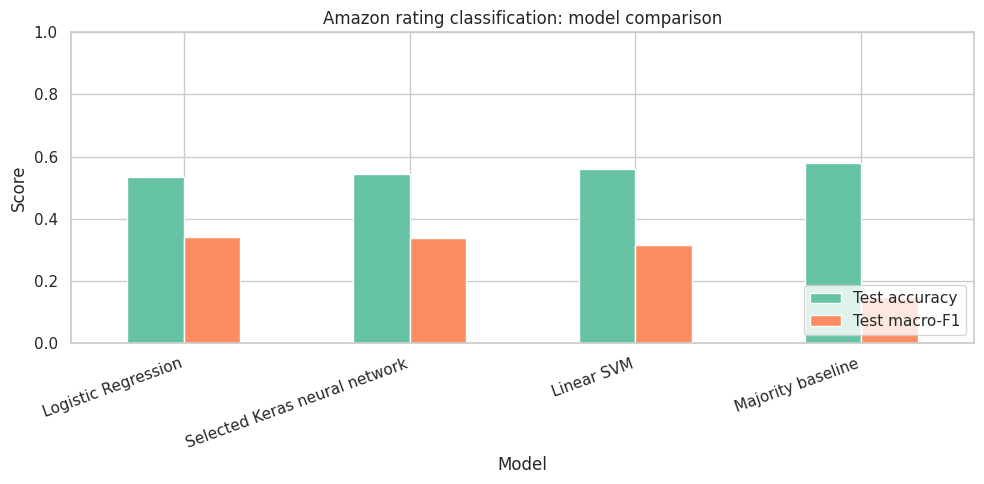

Highest test macro-F1 model: Logistic Regression


In [43]:
# Plot accuracy and macro-F1 side by side for easier comparison
comparison_plot = classification_comparison.set_index("Model")[["Test accuracy", "Test macro-F1"]]
comparison_plot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Amazon rating classification: model comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Highest test macro-F1 model:", classification_comparison.loc[0, "Model"])

# Per-rating evaluation for Logistic Regression and Linear SVM
The classification reports show precision, recall and F1-score for each star rating. Check whether the models can identify lower ratings as well as the more common ratings

In [44]:
# Detailed report: Logistic Regression
print("LOGISTIC REGRESSION — TEST SET")
print(classification_report(
    y_test_cls,
    logistic_test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
    zero_division=0
))

# Detailed report: Linear SVM
print("LINEAR SVM — TEST SET")
print(classification_report(
    y_test_cls,
    svm_test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
    zero_division=0
))


LOGISTIC REGRESSION — TEST SET
              precision    recall  f1-score   support

      1 star       0.36      0.50      0.42        18
     2 stars       0.17      0.22      0.19         9
     3 stars       0.09      0.11      0.10        19
     4 stars       0.30      0.21      0.25        38
     5 stars       0.76      0.74      0.75       116

    accuracy                           0.54       200
   macro avg       0.33      0.36      0.34       200
weighted avg       0.55      0.54      0.54       200

LINEAR SVM — TEST SET
              precision    recall  f1-score   support

      1 star       0.35      0.33      0.34        18
     2 stars       0.17      0.11      0.13         9
     3 stars       0.14      0.11      0.12        19
     4 stars       0.30      0.18      0.23        38
     5 stars       0.69      0.83      0.75       116

    accuracy                           0.56       200
   macro avg       0.33      0.31      0.32       200
weighted avg       0.51 

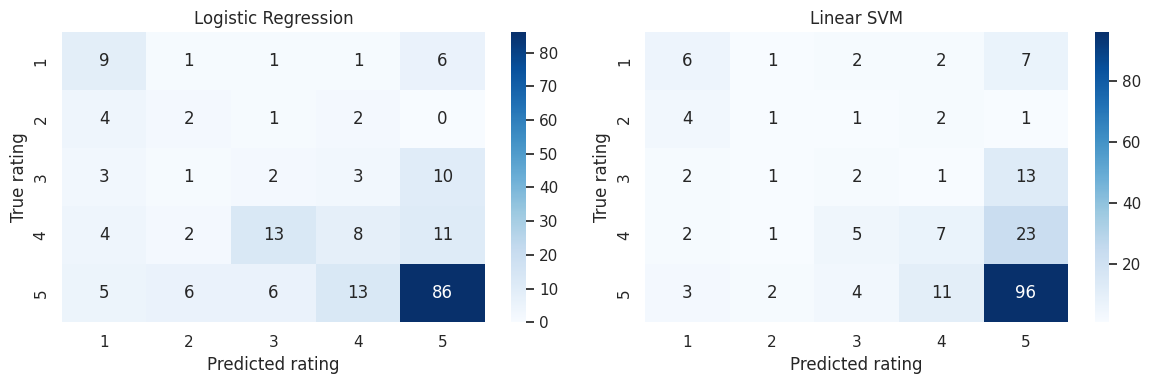

In [28]:
# Confusion matrices help show which star ratings are being confused
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, predictions, title in [
    (axes[0], logistic_test_pred, "Logistic Regression"),
    (axes[1], svm_test_pred, "Linear SVM")
]:
    cm = confusion_matrix(y_test_cls, predictions, labels=[0, 1, 2, 3, 4])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5]
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted rating")
    ax.set_ylabel("True rating")
plt.tight_layout()
plt.show()

# 10. Neural Network Regression — Predict Numeric Star Ratings

Classification treats ratings as separate categories, Regression treats ratings as numbers, so predicting 4 when the true rating is 5 is a smaller error than predicting 1. The regression MLP uses the same TF-IDF inputs and a linear output neuron.

# Evaluation metrics:

- MAE

Measures the average absolute difference between predicted and actual ratings.

- RMSE

Penalizes larger prediction errors more strongly.

- R² score

 Measures how well the model predicts ratings compared with predicting the mean rating; higher values generally indicate better performance.

- Predictions are clipped to the valid 1 - 5 star range for reporting.

Regression epochs completed: 16


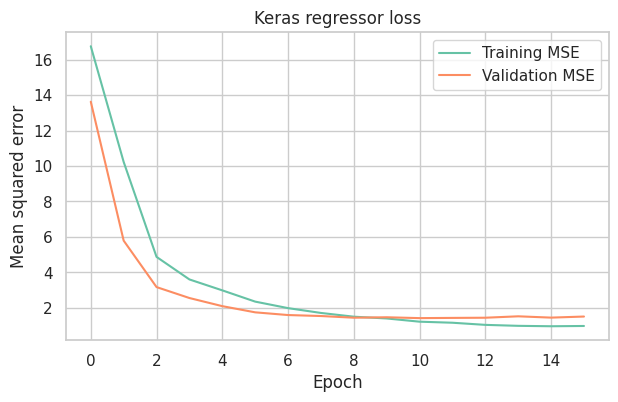

In [45]:
# Build and train a Keras regression MLP
def build_keras_regressor(input_dim, dropout_rate=0.30, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="linear")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mean_squared_error",
        metrics=["mean_absolute_error"]
    )
    return model

keras_regressor = build_keras_regressor(X_train.shape[1])
reg_history = keras_regressor.fit(
    X_train, y_train_reg,
    validation_data=(X_val, y_val_reg),
    epochs=40,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )],
    verbose=0
)
print("Regression epochs completed:", len(reg_history.history["loss"]))

plt.figure(figsize=(7, 4))
plt.plot(reg_history.history["loss"], label="Training MSE")
plt.plot(reg_history.history["val_loss"], label="Validation MSE")
plt.title("Keras regressor loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

The model completed 16 epochs before early stopping halted training because validation loss stopped improving. The best model weights were restored to help reduce overfitting.

In [46]:
# Evaluate the regressor against the mean-rating baseline
reg_pred = np.clip(keras_regressor.predict(X_test, verbose=0).ravel(), 1, 5)
mean_baseline_pred = np.clip(reg_baseline.predict(X_test), 1, 5)

regression_results = pd.DataFrame([
    {
        "Model": "Mean-rating baseline",
        "MAE": mean_absolute_error(y_test_reg, mean_baseline_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, mean_baseline_pred)),
        "R2": r2_score(y_test_reg, mean_baseline_pred)
    },
    {
        "Model": "Keras MLP regressor",
        "MAE": mean_absolute_error(y_test_reg, reg_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, reg_pred)),
        "R2": r2_score(y_test_reg, reg_pred)
    }
])
display(regression_results.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}"}))



,Model,MAE,RMSE,R2
0,Mean-rating baseline,1.014,1.284,-0.000
1,Keras MLP regressor,0.846,1.102,0.264


The Keras MLP regressor performed better than the mean-rating baseline. It achieved a lower MAE (0.846) and RMSE (1.102), meaning its rating predictions were more accurate. Its (R^2) of 0.264 indicates that it explains about 26.4% of the variation in customer ratings.The neural network improves rating prediction, although there is still room for improvement.

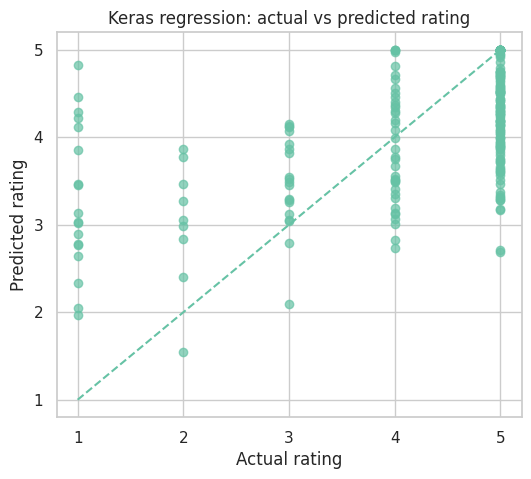

In [47]:
# Plot actual versus predicted ratings
plt.figure(figsize=(6, 5))
plt.scatter(y_test_reg, reg_pred, alpha=0.7)
plt.plot([1, 5], [1, 5], linestyle="--")
plt.xticks([1, 2, 3, 4, 5])
plt.yticks([1, 2, 3, 4, 5])
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title("Keras regression: actual vs predicted rating")
plt.show()

# 11. Framework comparison: PyTorch classifier
This section trains a comparable MLP in PyTorch on the same train, validation, test splits and the same TF-IDF features. The architecture is intentionally similar to the Keras classifier. PyTorch requires a manual training loop, while Keras provides .fit() and callbacks. For a fair comparison, both implementations use the same held-out test data and report accuracy and macro-F1.

In [48]:
# Train a similar MLP classifier in PyTorch when the framework is installed
torch_comparison = None

if TORCH_AVAILABLE:
    class TorchMLP(nn.Module):
        def __init__(self, input_dim, dropout_rate=0.30):
            super().__init__()
            self.network = nn.Sequential(
                nn.Linear(input_dim, 64),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
                nn.Linear(32, 5)
            )

        def forward(self, x):
            return self.network(x)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch_model = TorchMLP(X_train.shape[1]).to(device)
    optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train_cls, dtype=torch.long)
    )
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

    X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_t = torch.tensor(y_val_cls, dtype=torch.long).to(device)
    best_val_f1 = -1
    best_state = None
    patience, waiting = 5, 0
    torch_history = {"train_loss": [], "val_loss": []}

    for epoch in range(40):
        torch_model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = torch_model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(xb)

        train_loss = total_loss / len(train_dataset)
        torch_model.eval()
        with torch.no_grad():
            val_logits = torch_model(X_val_t)
            val_loss = criterion(val_logits, y_val_t).item()
            val_pred = val_logits.argmax(dim=1).cpu().numpy()
        val_f1 = f1_score(y_val_cls, val_pred, average="macro", zero_division=0)
        torch_history["train_loss"].append(train_loss)
        torch_history["val_loss"].append(val_loss)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in torch_model.state_dict().items()}
            waiting = 0
        else:
            waiting += 1
            if waiting >= patience:
                break

    if best_state is not None:
        torch_model.load_state_dict(best_state)

    torch_model.eval()
    with torch.no_grad():
        X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
        torch_test_pred = torch_model(X_test_t).argmax(dim=1).cpu().numpy()

    torch_comparison = {
        "Framework": "PyTorch",
        "Test accuracy": accuracy_score(y_test_cls, torch_test_pred),
        "Test macro-F1": f1_score(y_test_cls, torch_test_pred, average="macro", zero_division=0)
    }
    print("PyTorch device:", device)
    print("PyTorch epochs completed:", len(torch_history["train_loss"]))
    print("PyTorch test classification report:")
    print(classification_report(
        y_test_cls, torch_test_pred, labels=[0, 1, 2, 3, 4],
        target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
        zero_division=0
    ))
else:
    print("Skipping PyTorch: install torch in the active environment to run this comparison.")

PyTorch device: cpu
PyTorch epochs completed: 6
PyTorch test classification report:
              precision    recall  f1-score   support

      1 star       0.00      0.00      0.00        18
     2 stars       0.00      0.00      0.00         9
     3 stars       0.00      0.00      0.00        19
     4 stars       0.00      0.00      0.00        38
     5 stars       0.58      1.00      0.73       116

    accuracy                           0.58       200
   macro avg       0.12      0.20      0.15       200
weighted avg       0.34      0.58      0.43       200



The PyTorch model trained on the CPU for 6 epochs before early stopping. It achieved 58% test accuracy, but predicted only 5 star ratings, correctly identifying all 116 five star reviews while failing to identify lower ratings. Its macro-F1 score of 0.15 shows poor performance across the five rating classes.The model struggles with class imbalance and needs improvement to predict less common ratings reliably.

In [49]:
# Compare Keras and PyTorch test metrics when PyTorch was available
framework_rows = [{
    "Framework": "TensorFlow/Keras",
    "Test accuracy": accuracy_score(y_test_cls, best_test_pred),
    "Test macro-F1": f1_score(y_test_cls, best_test_pred, average="macro", zero_division=0)
}]
if torch_comparison is not None:
    framework_rows.append(torch_comparison)

framework_results = pd.DataFrame(framework_rows)
display(framework_results.style.format({"Test accuracy": "{:.3f}", "Test macro-F1": "{:.3f}"}))

,Framework,Test accuracy,Test macro-F1
0,TensorFlow/Keras,0.545,0.338
1,PyTorch,0.580,0.147


TensorFlow/Keras performed better overall in balanced classification, achieving a macro-F1 score of 0.338, compared with 0.147 for PyTorch. Although PyTorch had higher accuracy (58.0% vs. 54.5%), its low macro-F1 indicates poor performance on less common ratings.

TensorFlow/Keras is the better choice because it identifies rating classes more evenly, despite having slightly lower accuracy.

# Reflection and Final Summary

# 1. Natural Language Processing (NLP)

# What the common words and phrases say?
1. Most reviews are positive
- 768 out of 997 reviews (about 77%) are positive. Phrases such as work great, work well, and work fine are common.
2. Customers discuss products and features
- Frequent words and phrases include nook, kindle, screen, tablet, battery life, and wall mount.
3. Negation matters
- Words such as not, no, and never were retained because they can change a review's meaning.
4. Negative reviews highlight problems
- Phrases such as customer service, return, and replacement suggest possible support issues that need further investigation.
5. Phrases provide better context
- For example, battery life identifies a specific product feature more clearly than battery alone.

# What I did ;

1. Defined the goal
- Explored customer reviews and developed a prototype to classify sentiment, identify topics, and flag reviews that may need attention
2. Loaded and explored the data
- Examined 997 reviews, their columns, missing values, ratings, sentiment labels, and review lengths. No missing values were found.
3. Checked text quality
- Identified HTML codes and URLs that could affect text analysis.
4. Built the preprocessing function
- Decoded HTML, converted text to lowercase, removed URLs and punctuation, tokenized text, removed stopwords, and lemmatized words while keeping negation words.
5. Tested and validated cleaning
- Compared tokenization, stemming, and lemmatization. Cleaning reduced the number of tokens from 167,738 to 67,479, and no reviews became empty.
6. Identified common words
- Used word-frequency analysis to identify frequently mentioned products, features, and customer experiences.
7. Analysed phrases
- Used bigrams and trigrams to identify meaningful phrases such as battery life, customer service, and touch screen.
8. Compared sentiment language
- Identified phrases associated with positive and negative reviews to better understand customer experiences and possible complaints.
9. Built and evaluated a sentiment model
- Tested TF-IDF with Logistic Regression, Naive Bayes, DistilBERT, and a soft-voting ensemble. DistilBERT performed best among the evaluated models, with 86% accuracy and a Macro F1 of 0.541. The ensemble did not improve performance.
10. Created a routing demonstration
- Used keyword-based rules to group reviews into topics and compare negative-review rates across them.
11. Created a review-flagging step
- Flagged negative reviews so the support team can identify feedback that may require further investigation.

# Main results and limitations

1. Sentiment
- Positive reviews dominate the dataset, accounting for about 77% of reviews.
2. Model performance
- The models performed better on positive reviews than on neutral reviews. DistilBERT achieved the highest reported accuracy, but identifying negative and neutral reviews remains important for reliable support routing.
3. Support priorities
- Accessories received the most reviews (291), followed by Books & Reading (188). However, Customer Service / Returns had the highest negative-review rate (49.1%), followed by Apps & Software (19.8%). These areas deserve particular attention.
4. Routing limitations
- Topics are assigned using keyword rules rather than a trained topic-classification model. A review mentioning several topics may receive only one tag or be assigned to General.
5. Improvements needed
- Improve neutral review detection, examine incorrect predictions, refine topic tagging, and test the system on new reviews. Negative predictions should be reviewed before urgent action is taken.

# Final conclusion

This project demonstrates how NLP can analyse customer reviews, identify common topics and sentiments, and flag negative reviews for support team attention. The results show that Customer Service / Returns has the highest share of negative reviews, while Accessories receives the most reviews. These findings help the support team prioritize concerns and identify issues that need follow-up.

Although the system helps summarize feedback and guide support decisions, it still struggles with neutral reviews, and keyword-based topic tagging has limitations. Overall, the project provides a useful starting point for helping the support team understand customer feedback, prioritize problems, and respond more effectively, with further testing and human review needed before real-world use.The rreviews are also clearly classified

# 2.  Time Series Forecasting Project Summary: Amazon Review Activity

1. Business Goal

The goal of this project is to forecast monthly Amazon review activity accurately using stationarity tests, data transformations, and multiple time series models. The forecasts aim to support operational planning, resource allocation, and informed business decisions.

2. Data Understanding and Exploratory Analysis

The dataset contains 997 reviews and 9 columns, covering May 2000 to July 2014. There are no missing values or duplicate rows. The analysis focused on monthly review counts and average customer ratings, using 54 monthly observations from January 2010 to June 2014.

Review activity increased considerably in later years, particularly in 2012 and 2013. Monthly review counts fluctuated substantially, with a peak of approximately 46 reviews in one month. The average monthly customer rating was 4.08 out of 5, indicating generally positive feedback. The three-month rolling average also suggested an improvement in ratings over time.

Month over month review volume changes were highly variable, with a standard deviation of 84.5%. This volatility highlights the importance of forecasting future review volumes to help plan customer support and review moderation resources.

3. Stationarity and Seasonality

Rolling statistics, the Augmented Dickey-Fuller (ADF) test, and the KPSS test were used to assess stationarity. The raw and log-transformed review counts showed evidence of non-stationarity. First differencing of the log-transformed series and 12 month seasonal differencing provided stronger evidence of stationarity, making the transformed data more suitable for ARIMA-based analysis.

Seasonal decomposition suggested a possible yearly pattern, with December showing a positive seasonal effect and October a negative effect. However, these findings are exploratory because the dataset contains only about four and a half years of monthly observations. ACF and PACF plots showed generally weak autocorrelation, helping guide the selection of candidate models.

4. Model Development and Evaluation

Four forecasting approaches were compared: the Naïve baseline, ARIMA(0,1,0), Exponential Smoothing, and SARIMA(0,1,1) * (0,1,1,12). The last 12 months were held out for testing, while earlier observations were used for training. MAE, RMSE, and forecast bias were used to evaluate performance.

The Naive baseline and ARIMA achieved the best holdout results, with an MAE of 6.333 reviews and an RMSE of 7.895. Both under-forecasted by an average of 2 reviews, and ARIMA provided no improvement over the Naïve baseline. Exponential Smoothing recorded an MAE of 9.107, while SARIMA had the largest error, with an MAE of 19.537.

Walk-forward validation confirmed the findings: the Naïve baseline and ARIMA achieved the same mean MAE of 7.722 reviews, while SARIMA performed worst among the models in this validation. ARIMA residual diagnostics also showed no strong evidence of remaining autocorrelation, with a Ljung-Box p-value of 0.8602.

5. Final Forecast and Business Recommendations

The Naive baseline is selected as the preferred model because it performed as well as ARIMA while being simpler to implement and explain. The final model was refitted using all available monthly observations to forecast review activity for the following 12 months, from July 2014 to June 2015. The forecasts indicated approximately 15 reviews per month, with prediction intervals widening over time to reflect increasing uncertainty.

These forecasts can help businesses estimate review moderation workloads, plan customer support staffing, and allocate operational resources. However, the forecasts should be treated as planning estimates rather than exact predictions. The short historical series, substantial month-to-month fluctuations, and increasing forecast uncertainty limit confidence in long-term projections.

The sentiment analysis provided additional business context: positive reviews dominated throughout the observed period, generally accounting for around 70% - 90% of labelled reviews. Monitoring monthly sentiment alongside review volume could help identify changes in customer perceptions and potential service issues. However, sentiment was not included as a predictor in the forecasting models.

6. Conclusion

The project achieved its main analytical objective by examining monthly Amazon review activity, testing for stationarity, applying transformations, and comparing four forecasting approaches. The results showed that the simplest model,  Naive baseline, is the most practical choice among the tested models because it matched ARIMA's forecasting accuracy and outperformed the other approaches on the evaluation metrics.

The project demonstrates how time series forecasting can support operational planning and better informed business decisions. Future improvements could include collecting more historical data, testing additional forecasting models, monitoring changes in review patterns, and updating forecasts regularly as new observations become available.

# 3.  Neural Network

1. Business goal

The goal is to build and evaluate machine learning models that use Amazon review text to predict customer star ratings from 1 to 5. The project aimed to classify reviews into rating categories and predict numeric ratings. Different models were compared to identify the best performing approach and recommend improvements.

2. What I Did and the Outcomes

1. Data inspection:

Checked 997 reviews for missing values, duplicates, and rating distribution. The dataset had no missing values or duplicate rows, but most reviews were positive.

2. Text preparation:

Cleaned the review text and examined review lengths. The average review contained 146 words.

3. Data preparation:

Split the data into training, validation, and test sets and converted review text into numerical features using TF-IDF.

4. Baseline models:

 Created simple models to establish performance benchmarks.

5. Keras classification:

 Built a neural network to predict star ratings. The original model achieved 60% test accuracy but struggled with lower ratings.

6. Model improvement:

 Tested different dropout settings and class weighting. Class weighting improved the balance of classification performance across rating categories.

7. Keras regression: Built a neural network to predict numeric ratings. It performed better than the simple baseline.

8. PyTorch comparison:

 Trained a classification model using PyTorch. It struggled to predict ratings other than five stars.

9. Traditional machine-learning classifiers:

 Trained and evaluated Logistic Regression and Linear SVM using the same test data. Logistic Regression achieved the highest macro-F1 score among the models compared, while Linear SVM achieved higher accuracy than the trained neural-network classifiers.

# 3. Key Results

1. Classification: Keras Neural Network

The selected class-weighted Keras model achieved 54.5% test accuracy and a macro-F1 score of 0.338. Class weighting improved macro-F1 from 0.185 to 0.338. However, the model still struggled to identify lower ratings.

2. Regression: Keras Neural Network

The regression model achieved an MAE of 0.846, an RMSE of 1.102, and an R² of 0.264. Its predictions were, on average, about 0.85 stars away from the actual ratings. The model explained approximately 26.4% of the variation in customer ratings, performing better than the mean-rating baseline.

3. Keras and PyTorch Comparison

Keras achieved a macro-F1 score of 0.338, compared with 0.147 for PyTorch. Keras performed better at balancing predictions across rating categories, although both models struggled with less common ratings.

4. Traditional Machine-Learning Classifiers

Logistic Regression and Linear SVM were evaluated alongside the Keras neural network and majority baseline.

Logistic Regression achieved 53.5% accuracy and a macro-F1 score of 0.340, making it the best model based on macro-F1. Its performance was very close to Keras, which achieved 54.5% accuracy and a macro-F1 score of 0.338.

Linear SVM achieved 56% accuracy and a macro-F1 score of 0.315. The majority baseline achieved 58% accuracy but had a much lower macro-F1 score of 0.147. This shows that accuracy alone can be misleading when the dataset contains many more examples of some ratings than others.

The per-rating results also showed that both Logistic Regression and Linear SVM performed best on five star reviews, with an F1-score of 0.75. Logistic Regression performed better at identifying one star and two star reviews, while both models struggled with three star and four star reviews. Logistic Regression is therefore the preferred model based on balanced classification performance.

4. Business Findings

Most models recognise five-star reviews better than less common ratings.

The regression model predicted numeric ratings more accurately than the simple baseline.

Keras performed better than PyTorch in balanced classification performance.

Logistic Regression achieved the highest macro-F1 score among the compared classification models, showing that a traditional machine-learning approach can perform as well as or slightly better than a neural network on this dataset.

More data and improved text representations are needed to make the predictions more reliable.

# Final Conclusion
The regression model performed better than the baseline, while class weighting improved classification performance. Logistic Regression achieved the highest macro-F1 score of 0.340, closely followed by Keras at 0.338. However, all models struggled to identify less common ratings accurately. The business goal is partially achieved, and further improvements are needed before the models can reliably support customer satisfaction monitoring and business decisions.